# KLTN_EXP_099 — CHẠY KIỂM THỬ CUỐI CÙNG (P1–P2 theo Bảng GY.2)

**Thay đổi so với notebook gốc (không đổi mô hình, dữ liệu, hàm mất mát, quy tắc chọn cấu hình):**
1. `RUN_FINAL_TEST = True` — tập kiểm thử S13–S17 được dùng **đúng một lần**. Không sửa gì sau khi đã xem kết quả kiểm thử.
2. Ghi thời gian huấn luyện từng mạng con (`TRAIN_TIMES_S`).
3. Các ô **THESIS EXPORT** ở cuối notebook: xuất số liệu cho Bảng 3.1, 3.5, 3.8, hình hội tụ, tệp xác suất từng cửa sổ (dùng cho notebook 02 và 03).

Chạy: *Run All* trên Kaggle (GPU). Khi xong, tải thư mục `/kaggle/working/KLTN_EXP_099` (hoặc tệp `KLTN_EXP_099_outputs.zip`).


# KLTN_EXP_099
## EXP_050 base + compact motion-angle interaction specialist

### EXP_098 result
Validation S11-S12:
- accuracy=0.990225
- TN=1981, FP=9, FN=11, TP=45
- errors=20
- precision=0.833333
- recall=0.803571
- specificity=0.995477
- F1=0.818182
- F2=0.809353
- ROC-AUC=0.990551
- PR-AUC=0.848908
- threshold=0.886
- alpha_pmg=0.225

### Diagnosis
EXP_098 is rejected.

Relative to EXP_097:
- errors: 19 -> 20
- FN: 10 -> 11
- FP unchanged: 9
- ROC-AUC: 0.992023 -> 0.990551
- PR-AUC: 0.869242 -> 0.848908
- alpha_pmg collapsed from 0.800 -> 0.225

The phase-preserving real/imag spectral representation therefore degraded both
ranking and PMG usefulness. Do not sweep spectral encoding, bin count or
embedding dimension further.

### Current best
EXP_050 remains best:
- accuracy=0.992669
- TN=1984, FP=6, FN=9, TP=47
- errors=15
- precision=0.886792
- recall=0.839286
- specificity=0.996985
- F1=0.862385
- F2=0.848375
- ROC-AUC=0.991215
- PR-AUC=0.868255

### ONE controlled scientific change
Restore exact EXP_050 data, loss, optimizer, Transformer, PMG specialist
branches, augmentation, TTA, seed weighting, fusion and threshold selection.

Add one compact TRAINED interaction embedding inside PMG after the existing
motion and angle branches are pooled:

    motion pooled embedding m (96-D)
    angle pooled embedding a (32-D, post-pool LayerNorm)
        -> Dense(32, GELU) on m
        -> Dense(32, GELU) on a
        -> element-wise product
        -> LayerNorm
        -> concatenate with existing [pose, motion, geometry, angle]

This explicitly models co-occurrence between:
- how the body is moving, and
- the instantaneous articulation/posture encoded by bilateral joint angles.

Why:
Fall discrimination is not only "high motion" or "unusual angle" independently.
A fall is a coupled motion-posture event. Modeling their interaction may help
reduce false positives from fast non-fall movement and false negatives from
falls whose individual specialist scores are ambiguous.

No new raw feature is introduced. No preprocessing changes are made. The
interaction is derived only from existing EXP_050 PMG embeddings.

### Protocol unchanged
- Train S1-S10
- Validation S11-S12
- Test S13-S17
- subject-independent
- validation only for selection
- no test tuning
- RUN_FINAL_TEST=False
- dataset:
  /kaggle/input/datasets/nhathoanghuynh/upfall-camera2-processing
- preprocessing unchanged
- mirror augmentation=0.50
- subject balance strength=0.50
- positive weights unchanged
- Transformer unchanged
- optimizer/LR/callbacks unchanged
- TTA/seed weighting/fusion/threshold policy unchanged

Strict target: Validation Accuracy > 0.9958.
For n=2046, <=8 validation errors are required.

Scientific caution:
S11-S12 have already been reused across many experiment decisions. Any future
target crossing is provisional because of validation meta-overfitting risk.
S13-S17 remains untouched for tuning.


In [1]:

# ============================================================
# 1. IMPORTS + ROBUST SINGLE-GPU STRATEGY
# ============================================================

import os

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_GPU_THREAD_MODE', 'gpu_private')

import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision

tf.get_logger().setLevel('ERROR')

print('TensorFlow:', tf.__version__)

PHYSICAL_GPUS = tf.config.list_physical_devices('GPU')
LOGICAL_GPUS = tf.config.list_logical_devices('GPU')

print('Physical GPUs detected:', PHYSICAL_GPUS)
print('Logical GPUs available:', LOGICAL_GPUS)

if PHYSICAL_GPUS:
    for gpu in PHYSICAL_GPUS:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

    mixed_precision.set_global_policy('mixed_float16')

    strategy = tf.distribute.OneDeviceStrategy(
        device='/GPU:0'
    )
    GPU_DEVICE = '/GPU:0'
else:
    mixed_precision.set_global_policy('float32')
    strategy = tf.distribute.get_strategy()
    GPU_DEVICE = '/CPU:0'
    print('WARNING: No GPU detected; CPU fallback is active.')

print('Mixed precision policy:', mixed_precision.global_policy())
print('Distribution strategy:', type(strategy).__name__)
print('Replicas:', strategy.num_replicas_in_sync)
print('Primary compute device:', GPU_DEVICE)

if PHYSICAL_GPUS:
    assert strategy.num_replicas_in_sync == 1
    assert isinstance(
        strategy,
        tf.distribute.OneDeviceStrategy
    )

AUTOTUNE = tf.data.AUTOTUNE


TensorFlow: 2.20.0
Physical GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Logical GPUs available: [LogicalDevice(name='/device:GPU:0', device_type='GPU'), LogicalDevice(name='/device:GPU:1', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
Distribution strategy: OneDeviceStrategy
Replicas: 1
Primary compute device: /GPU:0


I0000 00:00:1795496099.970063      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795496099.974090      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:

# ============================================================
# 2. CONFIG — KLTN_EXP_024
# ============================================================

DATA_DIR = Path('/kaggle/input/datasets/anhoa1/upfall-camera2-processing')
OUTPUT_DIR = Path('/kaggle/working/KLTN_EXP_099')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / 'upfall_train.npz'
VAL_PATH   = DATA_DIR / 'upfall_val.npz'
TEST_PATH  = DATA_DIR / 'upfall_test.npz'
CLASS_WEIGHT_PATH = DATA_DIR / 'class_weight.json'

EXPERIMENT_NAME = "KLTN_EXP_099"
TARGET_VALIDATION_ACCURACY = 0.9958
RUN_FINAL_TEST = True   # P1: kiểm thử S13–S17 đúng MỘT lần, cấu hình EXP_099 giữ nguyên

SEQ_LEN = 30
NUM_KP = 17
NUM_FEATURES = 51
BATCH_SIZE = 128
GLOBAL_BATCH_SIZE = BATCH_SIZE
EPOCHS = 100

TRAIN_DROP_REMAINDER = False
EVAL_DROP_REMAINDER = False
TF_DATA_SHUFFLE_BUFFER = 16384
STEPS_PER_EXECUTION = 1
PER_REPLICA_BATCH = GLOBAL_BATCH_SIZE

BASELINE = {
    'accuracy': 0.983911,
    'precision': 0.595041,
    'recall': 0.720000,
    'specificity': 0.989543,
    'f1': 0.651584,
    'f2': 0.690979,
    'roc_auc': 0.979494,
    'pr_auc': 0.618362,
}

V11_REFERENCE = {
    'accuracy': 0.985792,
    'precision': 0.640351,
    'recall': 0.730000,
    'specificity': 0.991251,
    'f1': 0.682243,
    'f2': 0.710117,
    'roc_auc': 0.979646,
    'pr_auc': 0.685361,
}

EXP018_VALIDATION_REFERENCE = {
    'accuracy': 0.988759,
    'precision': 0.770492,
    'recall': 0.839286,
    'specificity': 0.992965,
    'f1': 0.803419,
    'f2': 0.824561,
    'roc_auc': 0.990057,
    'pr_auc': 0.841883,
}

EXP023_VALIDATION_REFERENCE = {
    'accuracy': 0.988759,
    'precision': 0.779661,
    'recall': 0.821429,
    'specificity': 0.993467,
    'f1': 0.800000,
    'f2': 0.812721,
    'roc_auc': 0.981999,
    'pr_auc': 0.821318,
}

EXP024_VALIDATION_REFERENCE = {
    'accuracy': 0.9897360703812317,
    'precision': 0.7692307692307693,
    'recall': 0.8928571428571429,
    'specificity': 0.992462311557789,
    'f1': 0.8264462809917356,
    'f2': 0.8650519031141869,
    'roc_auc': 0.9939249820531227,
    'pr_auc': 0.8616835405297009,
}

TRANSFORMER_SEEDS = [42, 777]
TRANSFORMER_LR = 5e-4
TRANSFORMER_POS_WEIGHT = 6.0

PMG_SEEDS = [42, 123, 2026]
PMG_LR = 3e-4
PMG_POS_WEIGHT = 8.0

D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
NUM_BLOCKS = 3
DROPOUT = 0.20

PMG_D_MODEL = 96
PMG_FF = 192
PMG_BLOCKS = 2
TCN_CHANNELS = [64, 96, 96]
TCN_DILATIONS = [1, 2, 4]

BASE_GEOMETRY_DIM = 9
TRANSITION_FEATURE_DIM = 12
GEOMETRY_FEATURE_DIM = BASE_GEOMETRY_DIM + TRANSITION_FEATURE_DIM

TRAIN_MIRROR_FRACTION = 0.50
TRAIN_AUG_SEED = 20261027

SUBJECT_BALANCE_STRENGTH = 0.50
SUBJECT_BALANCE_MIN = 0.75
SUBJECT_BALANCE_MAX = 1.25

THRESHOLD_MIN = 0.50
THRESHOLD_MAX = 0.99
THRESHOLD_STEP = 0.001

ALPHAS = np.round(np.arange(0.0, 1.0001, 0.025), 3)
TR_WEIGHT_STEP = 0.025
PMG_WEIGHT_STEP = 0.05

MIN_VAL_PRECISION = 0.65
MIN_VAL_RECALL = 0.82
MIN_VAL_SPECIFICITY = 0.990
MIN_VAL_F1 = 0.70
MIN_VAL_F2 = 0.74
MIN_SUBJECT_RECALL = 0.70
MIN_SUBJECT_SPECIFICITY = 0.985

TTA_BETAS = np.round(np.arange(0.0, 0.5001, 0.05), 3)
TTA_MODES = ['prob', 'logit']
TTA_MAX_PR_DROP = 0.002
TTA_MAX_ROC_DROP = 0.002

RUNTIME_FIX = {
    'distribution_strategy': 'OneDeviceStrategy_GPU0',
    'visible_device_mutation': False,
    'mixed_precision': True,
    'steps_per_execution': 1,
    'train_drop_remainder': False,
    'eval_drop_remainder': False,
}

for p in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    print(p.name, '->', p.exists())

print('Experiment:', EXPERIMENT_NAME)
print('Strategy:', type(strategy).__name__)


EXP026_VALIDATION_REFERENCE = {
    'accuracy': 0.9897360703812317,
    'precision': 0.7966101694915254,
    'recall': 0.8392857142857143,
    'specificity': 0.9939698492462311,
    'f1': 0.8173913043478261,
    'f2': 0.8303886925795053,
    'roc_auc': 0.9899856424982052,
    'pr_auc': 0.8552146873018499,
}


EXP027_VALIDATION_REFERENCE = {
    'accuracy': 0.9868035190615836,
    'precision': 0.7230769230769231,
    'recall': 0.8392857142857143,
    'specificity': 0.9909547738693467,
    'f1': 0.7768595041322314,
    'f2': 0.8131487889273357,
    'roc_auc': 0.9912867910983489,
    'pr_auc': 0.8574372126289613,
}

# Accuracy-first validation guardrails.
ACC_FIRST_MIN_PRECISION = 0.65
ACC_FIRST_MIN_RECALL = 0.80
ACC_FIRST_MIN_SPECIFICITY = 0.990
ACC_FIRST_MIN_F1 = 0.70
ACC_FIRST_MIN_F2 = 0.74
ACC_FIRST_MIN_SUBJECT_RECALL = 0.65
ACC_FIRST_MIN_SUBJECT_SPECIFICITY = 0.985


EXP028_VALIDATION_REFERENCE = {
    'accuracy': 0.9897360703812317,
    'precision': 0.7868852459016393,
    'recall': 0.8571428571428571,
    'specificity': 0.9934673366834171,
    'f1': 0.8205128205128205,
    'f2': 0.8421052631578947,
    'roc_auc': 0.9920585068198134,
    'pr_auc': 0.8638514559855728,
}

EXP029_VALIDATION_REFERENCE={'accuracy':0.9916911045943304,'precision':0.8679245283018868,'recall':0.8214285714285714,'specificity':0.9964824120603015,'f1':0.8440366972477065,'f2':0.8303249097472925,'roc_auc':0.9925340990667624,'pr_auc':0.873987046259881}
EXP045_VALIDATION_REFERENCE={'accuracy':0.990713587487781,'precision':0.8490566037735849,'recall':0.8035714285714286,'specificity':0.9959798994974874,'f1':0.8256880733944955,'f2':0.8122743682310469,'roc_auc':0.9905509691313712,'pr_auc':0.8535981168806794}
ANGLE_FEATURE_DIM=8
ANGLE_FEATURES='cos_relative_elbow_shoulder_hip_knee_bilateral'

EXP046_VALIDATION_REFERENCE={
    'accuracy':0.9912023460410557,'precision':0.8064516129032258,
    'recall':0.8928571428571429,'specificity':0.9939698492462311,
    'f1':0.847457627118644,'f2':0.8741258741258742,
    'roc_auc':0.9943377602297201,'pr_auc':0.8732775616502608,
}
EXP049_VALIDATION_REFERENCE={
    'accuracy':0.9902248289345064,'precision':0.8333333333333334,
    'recall':0.8035714285714286,'specificity':0.9954773869346734,
    'f1':0.8181818181818182,'f2':0.8093525179856115,
    'roc_auc':0.9879307250538407,'pr_auc':0.847125276642275,
}
ANGLE_POST_POOL_NORMALIZATION='layer_norm'


# ============================================================
# EXP_099 CONTROLLED CHANGE — motion-angle interaction specialist
# ============================================================
MOTION_ANGLE_INTERACTION_DIM = 32
MOTION_ANGLE_INTERACTION_MODE = 'project32_elementwise_product_layernorm'

EXP050_VALIDATION_REFERENCE = {
    'accuracy':0.9926686217008798,
    'precision':0.8867924528301887,
    'recall':0.8392857142857143,
    'specificity':0.9969849246231156,
    'f1':0.8623853211009175,
    'f2':0.8483754512635379,
    'roc_auc':0.9912150035893754,
    'pr_auc':0.868254612346474,
}
EXP097_VALIDATION_REFERENCE = {
    'accuracy':0.990713587487781,
    'precision':0.8363636363636363,
    'recall':0.8214285714285714,
    'specificity':0.9954773869346734,
    'f1':0.8288288288288288,
    'f2':0.8243727598566308,
    'roc_auc':0.9920226130653266,
    'pr_auc':0.8692424068488713,
}
EXP098_VALIDATION_REFERENCE = {
    'accuracy':0.9902248289345064,
    'precision':0.8333333333333334,
    'recall':0.8035714285714286,
    'specificity':0.9954773869346734,
    'f1':0.8181818181818182,
    'f2':0.8093525179856115,
    'roc_auc':0.9905509691313711,
    'pr_auc':0.8489075862972171,
}


# P1 — đo thời gian huấn luyện từng mạng con (cho Bảng 3.1)
import time
TRAIN_TIMES_S = {}


upfall_train.npz -> True
upfall_val.npz -> True
upfall_test.npz -> True
Experiment: KLTN_EXP_099
Strategy: OneDeviceStrategy


In [3]:

EXPECTED_EXPERIMENT_ID='KLTN_EXP_099'

assert EXPERIMENT_NAME==EXPECTED_EXPERIMENT_ID
assert RUN_FINAL_TEST is True
assert ANGLE_FEATURE_DIM==8
assert ANGLE_POST_POOL_NORMALIZATION=='layer_norm'

assert MOTION_ANGLE_INTERACTION_DIM==32
assert MOTION_ANGLE_INTERACTION_MODE=='project32_elementwise_product_layernorm'

print('NOTEBOOK_IDENTITY :',EXPERIMENT_NAME)
print('RUN_FINAL_TEST     :',RUN_FINAL_TEST)
print('MOTION_ANGLE_INTERACTION_DIM:',MOTION_ANGLE_INTERACTION_DIM)
print('MOTION_ANGLE_INTERACTION_MODE:',MOTION_ANGLE_INTERACTION_MODE)


NOTEBOOK_IDENTITY : KLTN_EXP_099
RUN_FINAL_TEST     : True
MOTION_ANGLE_INTERACTION_DIM: 32
MOTION_ANGLE_INTERACTION_MODE: project32_elementwise_product_layernorm


In [4]:
# ============================================================
# 3. LOAD + VERIFY DATA
# ============================================================

def load_npz(path):
    d = np.load(path, allow_pickle=True)
    if 'X' not in d.files or 'y' not in d.files:
        raise KeyError(f'{path.name} missing X/y. Keys: {d.files}')

    X = d['X'].astype(np.float32)
    y = d['y'].astype(np.int32).reshape(-1)

    meta = {}
    for k in ['subject', 'activity', 'trial', 'camera']:
        if k in d.files:
            meta[k] = np.asarray(d[k]).reshape(-1)
    return X, y, meta

X_train, y_train, meta_train = load_npz(TRAIN_PATH)
X_val, y_val, meta_val = load_npz(VAL_PATH)
X_test, y_test, meta_test = load_npz(TEST_PATH)

print('Train:', X_train.shape, np.unique(y_train, return_counts=True))
print('Val  :', X_val.shape, np.unique(y_val, return_counts=True))
print('Test :', X_test.shape, np.unique(y_test, return_counts=True))

for X, y in [(X_train,y_train),(X_val,y_val),(X_test,y_test)]:
    assert X.shape[1:] == (30,51)
    assert len(X) == len(y)
    assert np.isnan(X).sum() == 0
    assert np.isinf(X).sum() == 0

if all('subject' in m for m in [meta_train, meta_val, meta_test]):
    tr_s = set(np.unique(meta_train['subject']).astype(int))
    va_s = set(np.unique(meta_val['subject']).astype(int))
    te_s = set(np.unique(meta_test['subject']).astype(int))
    print('Train subjects:', sorted(tr_s))
    print('Val subjects  :', sorted(va_s))
    print('Test subjects :', sorted(te_s))
    assert tr_s.isdisjoint(va_s)
    assert tr_s.isdisjoint(te_s)
    assert va_s.isdisjoint(te_s)
    print('No subject leakage.')


# ------------------------------------------------------------
# V16 LEFT/RIGHT SKELETON MIRROR
# ------------------------------------------------------------

# Selected 17-joint order:
# 0 nose
# 1/2 shoulder L/R
# 3/4 elbow L/R
# 5/6 wrist L/R
# 7/8 hip L/R
# 9/10 knee L/R
# 11/12 ankle L/R
# 13/14 heel L/R
# 15/16 foot index L/R
LR_SWAP = np.array(
    [0,2,1,4,3,6,5,8,7,10,9,12,11,14,13,16,15],
    dtype=np.int32
)
LR_SWAP_TF = tf.constant(LR_SWAP, dtype=tf.int32)

@tf.function(jit_compile=True, reduce_retracing=True)
def _mirror_skeleton_gpu(x):
    x = tf.cast(x, tf.float32)
    sk = tf.reshape(
        x,
        (-1, SEQ_LEN, NUM_KP, 3)
    )

    hip_center_x = (
        sk[:, :, 7, 0]
        + sk[:, :, 8, 0]
    ) / 2.0

    mirrored_x = (
        2.0 * hip_center_x[:, :, None]
        - sk[:, :, :, 0]
    )

    sk = tf.concat(
        [
            mirrored_x[..., None],
            sk[:, :, :, 1:3],
        ],
        axis=-1
    )

    sk = tf.gather(
        sk,
        LR_SWAP_TF,
        axis=2
    )

    return tf.reshape(
        sk,
        (-1, SEQ_LEN, NUM_FEATURES)
    )


def mirror_skeleton_sequence(X):
    """
    GPU-accelerated left/right skeleton mirror.
    Returns float32 NumPy because later reporting/search code uses NumPy.
    """
    with tf.device(GPU_DEVICE):
        out = _mirror_skeleton_gpu(
            tf.convert_to_tensor(
                X,
                dtype=tf.float32
            )
        )
    return out.numpy().astype(np.float32, copy=False)


X_val_mirror = mirror_skeleton_sequence(X_val)
X_test_mirror = mirror_skeleton_sequence(X_test)

print('Mirror val :', X_val_mirror.shape)
print('Mirror test:', X_test_mirror.shape)

assert X_val_mirror.shape == X_val.shape
assert X_test_mirror.shape == X_test.shape
assert np.isnan(X_val_mirror).sum() == 0
assert np.isnan(X_test_mirror).sum() == 0

# ============================================================
# EXP_029 SYMMETRY AUGMENTATION + TRAIN SUBJECT TRACKING
# ============================================================

if 'subject' not in meta_train:
    raise KeyError('Train subject IDs are required for EXP_029.')

TRAIN_SUBJECT_ORIGINAL = np.asarray(
    meta_train['subject']
).reshape(-1).astype(np.int32)

def make_stratified_symmetry_train_with_subjects(
    X, y, subjects, fraction=0.50, seed=20261027
):
    rng = np.random.default_rng(seed)
    selected = []

    for cls in sorted(np.unique(y)):
        cls_idx = np.flatnonzero(y == cls)
        n_take = int(round(len(cls_idx) * float(fraction)))
        n_take = max(1, min(n_take, len(cls_idx)))
        take = rng.choice(cls_idx, size=n_take, replace=False)
        selected.append(np.sort(take))

    selected = np.concatenate(selected)

    X_extra = mirror_skeleton_sequence(X[selected])
    y_extra = y[selected].copy()
    s_extra = subjects[selected].copy()

    X_aug = np.concatenate([X, X_extra], axis=0).astype(np.float32)
    y_aug = np.concatenate([y, y_extra], axis=0).astype(np.int32)
    s_aug = np.concatenate([subjects, s_extra], axis=0).astype(np.int32)

    order = rng.permutation(len(y_aug))

    return X_aug[order], y_aug[order], s_aug[order], selected


(
    X_train_exp046,
    y_train_exp046,
    TRAIN_SUBJECT_EXP046,
    train_aug_selected,
) = make_stratified_symmetry_train_with_subjects(
    X_train,
    y_train,
    TRAIN_SUBJECT_ORIGINAL,
    fraction=TRAIN_MIRROR_FRACTION,
    seed=TRAIN_AUG_SEED
)


def compute_class_conditional_subject_factors(
    y,
    subjects,
    strength=0.50,
    min_factor=0.75,
    max_factor=1.25,
):
    y = np.asarray(y).reshape(-1)
    subjects = np.asarray(subjects).reshape(-1)

    factors = np.ones(len(y), dtype=np.float32)
    rows = []

    for cls in sorted(np.unique(y)):
        cls_mask = (y == cls)
        cls_subjects = subjects[cls_mask]

        unique_s, counts = np.unique(
            cls_subjects,
            return_counts=True
        )

        mean_count = float(np.mean(counts))
        raw_map = {}

        for sid, count in zip(unique_s, counts):
            raw = (mean_count / float(count)) ** float(strength)
            raw = float(np.clip(raw, min_factor, max_factor))
            raw_map[int(sid)] = raw

        cls_raw = np.asarray(
            [raw_map[int(s)] for s in cls_subjects],
            dtype=np.float64
        )

        cls_raw /= max(float(cls_raw.mean()), 1e-12)
        factors[cls_mask] = cls_raw.astype(np.float32)

        for sid, count in zip(unique_s, counts):
            sid_local = (cls_subjects == sid)
            rows.append({
                'class': int(cls),
                'subject': int(sid),
                'samples': int(count),
                'subject_factor': float(cls_raw[sid_local][0]),
            })

    return factors, pd.DataFrame(rows)


SUBJECT_BALANCE_WEIGHTS_EXP046, subject_balance_df = (
    compute_class_conditional_subject_factors(
        y_train_exp046,
        TRAIN_SUBJECT_EXP046,
        strength=SUBJECT_BALANCE_STRENGTH,
        min_factor=SUBJECT_BALANCE_MIN,
        max_factor=SUBJECT_BALANCE_MAX,
    )
)

print('\n' + '='*90)
print('EXP_029 TRAIN DATA + SUBJECT BALANCE')
print('='*90)
print('Original train:', X_train.shape)
print('Symmetry train:', X_train_exp046.shape)
print('Subjects:', sorted(np.unique(TRAIN_SUBJECT_EXP046).tolist()))
print(
    'Subject factor range:',
    float(SUBJECT_BALANCE_WEIGHTS_EXP046.min()),
    '->',
    float(SUBJECT_BALANCE_WEIGHTS_EXP046.max())
)
print('Validation untouched:', X_val.shape)
print('Test untouched:', X_test.shape)

display(subject_balance_df.sort_values(['class', 'subject']))

subject_balance_df.to_csv(
    OUTPUT_DIR/'exp099_subject_balance_weights.csv',
    index=False
)

assert len(X_train_exp046) == len(y_train_exp046)
assert len(y_train_exp046) == len(TRAIN_SUBJECT_EXP046)
assert len(y_train_exp046) == len(SUBJECT_BALANCE_WEIGHTS_EXP046)
assert np.isnan(X_train_exp046).sum() == 0
assert np.isinf(X_train_exp046).sum() == 0


Train: (10407, 30, 51) (array([0, 1], dtype=int32), array([10093,   314]))
Val  : (2046, 30, 51) (array([0, 1], dtype=int32), array([1990,   56]))
Test : (4786, 30, 51) (array([0, 1], dtype=int32), array([4686,  100]))
Train subjects: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Val subjects  : [np.int64(11), np.int64(12)]
Test subjects : [np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17)]
No subject leakage.


I0000 00:00:1795496102.452324      49 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Mirror val : (2046, 30, 51)
Mirror test: (4786, 30, 51)

EXP_029 TRAIN DATA + SUBJECT BALANCE
Original train: (10407, 30, 51)
Symmetry train: (15610, 30, 51)
Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Subject factor range: 0.8202213644981384 -> 1.327835202217102
Validation untouched: (2046, 30, 51)
Test untouched: (4786, 30, 51)


,class,subject,samples,subject_factor
0,0,1,1664,0.954685
1,0,2,1501,1.005186
2,0,3,1622,0.966966
3,0,4,1499,1.005856
4,0,5,1627,0.965479
5,0,6,1235,1.108162
6,0,7,1581,0.979424
7,0,8,1374,1.050614
8,0,9,1579,0.980044
9,0,10,1457,1.020251


In [5]:

# ============================================================
# 4. PMG FEATURES — GPU VECTORIZED
# ============================================================

@tf.function(jit_compile=True, reduce_retracing=True)
def _angle_3pts_tf(a, b, c, eps=1e-6):
    ba = a - b
    bc = c - b

    dot = tf.reduce_sum(
        ba * bc,
        axis=-1
    )

    den = (
        tf.norm(ba, axis=-1)
        * tf.norm(bc, axis=-1)
    )

    cosv = tf.clip_by_value(
        dot / tf.maximum(den, eps),
        -1.0,
        1.0
    )

    return tf.acos(cosv)


@tf.function(jit_compile=True, reduce_retracing=True)
def _build_features_gpu(x):
    x = tf.cast(x, tf.float32)

    n = tf.shape(x)[0]

    sk = tf.reshape(
        x,
        (n, SEQ_LEN, NUM_KP, 3)
    )

    xy = sk[..., :2]
    pose = x

    # Velocity without tf.experimental.numpy.diff.
    vel_rest = xy[:, 1:] - xy[:, :-1]
    vel = tf.concat(
        [
            tf.zeros_like(xy[:, :1]),
            vel_rest
        ],
        axis=1
    )

    acc_rest = vel[:, 1:] - vel[:, :-1]
    acc = tf.concat(
        [
            tf.zeros_like(vel[:, :1]),
            acc_rest
        ],
        axis=1
    )

    motion = tf.concat(
        [
            tf.reshape(
                vel,
                (n, SEQ_LEN, 34)
            ),
            tf.reshape(
                acc,
                (n, SEQ_LEN, 34)
            ),
        ],
        axis=-1
    )

    l_sh = xy[:, :, 1]
    r_sh = xy[:, :, 2]

    l_hip = xy[:, :, 7]
    r_hip = xy[:, :, 8]

    l_knee = xy[:, :, 9]
    r_knee = xy[:, :, 10]

    l_ank = xy[:, :, 11]
    r_ank = xy[:, :, 12]

    sh_mid = (
        l_sh + r_sh
    ) / 2.0

    hip_mid = (
        l_hip + r_hip
    ) / 2.0

    x_all = xy[..., 0]
    y_all = xy[..., 1]

    body_width = (
        tf.reduce_max(x_all, axis=2)
        - tf.reduce_min(x_all, axis=2)
    )

    body_height = (
        tf.reduce_max(y_all, axis=2)
        - tf.reduce_min(y_all, axis=2)
    )

    aspect = (
        body_width
        / tf.maximum(body_height, 1e-6)
    )

    shoulder_width = tf.norm(
        l_sh-r_sh,
        axis=-1
    )

    hip_width = tf.norm(
        l_hip-r_hip,
        axis=-1
    )

    torso_len = tf.norm(
        sh_mid-hip_mid,
        axis=-1
    )

    torso_vec = sh_mid-hip_mid

    torso_angle = tf.atan2(
        tf.abs(torso_vec[..., 0]),
        tf.abs(torso_vec[..., 1]) + 1e-6
    )

    left_knee = _angle_3pts_tf(
        l_hip,
        l_knee,
        l_ank
    )

    right_knee = _angle_3pts_tf(
        r_hip,
        r_knee,
        r_ank
    )

    geometry_base = tf.stack(
        [
            body_width,
            body_height,
            aspect,
            shoulder_width,
            hip_width,
            torso_len,
            torso_angle,
            left_knee,
            right_knee,
        ],
        axis=-1
    )

    # --------------------------------------------------------
    # EXP_029: transition-enriched geometry
    # --------------------------------------------------------
    # The preprocessed skeleton is hip-centered, so these
    # features intentionally rely on RELATIVE pose dynamics
    # rather than absolute camera/world translation.

    def first_difference(v):
        return tf.concat(
            [
                tf.zeros_like(v[:, :1]),
                v[:, 1:] - v[:, :-1],
            ],
            axis=1
        )

    speed = tf.norm(
        vel,
        axis=-1
    )
    accel_mag = tf.norm(
        acc,
        axis=-1
    )

    mean_speed = tf.reduce_mean(
        speed,
        axis=2
    )
    max_speed = tf.reduce_max(
        speed,
        axis=2
    )
    mean_accel = tf.reduce_mean(
        accel_mag,
        axis=2
    )
    max_accel = tf.reduce_max(
        accel_mag,
        axis=2
    )

    lower_extension = (
        tf.norm(l_hip-l_ank, axis=-1)
        + tf.norm(r_hip-r_ank, axis=-1)
    ) / 2.0

    d_torso_angle = first_difference(
        torso_angle
    )
    d_aspect = first_difference(
        aspect
    )
    d_body_height = first_difference(
        body_height
    )
    d_lower_extension = first_difference(
        lower_extension
    )
    d_mean_speed = first_difference(
        mean_speed
    )
    d_torso_len = first_difference(
        torso_len
    )

    transition = tf.stack(
        [
            d_torso_angle,
            tf.abs(d_torso_angle),
            d_aspect,
            d_body_height,
            lower_extension,
            d_lower_extension,
            mean_speed,
            max_speed,
            mean_accel,
            max_accel,
            d_mean_speed,
            d_torso_len,
        ],
        axis=-1
    )

    geometry = tf.concat(
        [
            geometry_base,
            transition,
        ],
        axis=-1
    )

    # EXP_099 controlled change: bilateral relative joint angles.
    # cos(theta) avoids angular wrap-around and is scale invariant.
    l_elbow_cos = tf.cos(_angle_3pts_tf(l_sh, xy[:, :, 3], xy[:, :, 5]))
    r_elbow_cos = tf.cos(_angle_3pts_tf(r_sh, xy[:, :, 4], xy[:, :, 6]))
    l_shoulder_cos = tf.cos(_angle_3pts_tf(xy[:, :, 3], l_sh, l_hip))
    r_shoulder_cos = tf.cos(_angle_3pts_tf(xy[:, :, 4], r_sh, r_hip))
    l_hip_cos = tf.cos(_angle_3pts_tf(l_sh, l_hip, l_knee))
    r_hip_cos = tf.cos(_angle_3pts_tf(r_sh, r_hip, r_knee))
    l_knee_cos = tf.cos(_angle_3pts_tf(l_hip, l_knee, l_ank))
    r_knee_cos = tf.cos(_angle_3pts_tf(r_hip, r_knee, r_ank))

    angles = tf.stack(
        [
            l_elbow_cos, r_elbow_cos,
            l_shoulder_cos, r_shoulder_cos,
            l_hip_cos, r_hip_cos,
            l_knee_cos, r_knee_cos,
        ],
        axis=-1
    )

    return (
        tf.cast(pose, tf.float32),
        tf.cast(motion, tf.float32),
        tf.cast(geometry, tf.float32),
        tf.cast(angles, tf.float32),
    )


def build_features(X):
    """
    Feature extraction executes on GPU.
    NumPy copies are returned for tf.data / sklearn compatibility.
    """
    with tf.device(GPU_DEVICE):
        pose, motion, geometry, angles = _build_features_gpu(
            tf.convert_to_tensor(
                X,
                dtype=tf.float32
            )
        )

    return (
        pose.numpy(),
        motion.numpy(),
        geometry.numpy(),
        angles.numpy(),
    )


P_train, M_train, G_train, A_train = build_features(X_train)
P_val, M_val, G_val, A_val = build_features(X_val)
P_test, M_test, G_test, A_test = build_features(X_test)

print('Pose    :', P_train.shape)
print('Motion  :', M_train.shape)
print('Geometry:', G_train.shape)
assert G_train.shape[-1] == GEOMETRY_FEATURE_DIM
assert G_val.shape[-1] == GEOMETRY_FEATURE_DIM
assert G_test.shape[-1] == GEOMETRY_FEATURE_DIM

# Mirrored inference features.
P_val_m, M_val_m, G_val_m, A_val_m = build_features(X_val_mirror)
P_test_m, M_test_m, G_test_m, A_test_m = build_features(X_test_mirror)

print('Mirror PMG pose    :', P_val_m.shape)
print('Mirror PMG motion  :', M_val_m.shape)
print('Mirror PMG geometry:', G_val_m.shape)

# V18 augmented training features.
P_train_aug, M_train_aug, G_train_aug, A_train_aug = build_features(
    X_train_exp046
)

print('\nV18 augmented PMG features')
print('Pose    :', P_train_aug.shape)
print('Motion  :', M_train_aug.shape)
print('Geometry:', G_train_aug.shape)

P_train_exp046 = P_train_aug
M_train_exp046 = M_train_aug
G_train_exp046 = G_train_aug
A_train_exp046 = A_train_aug

print('\nEXP_029 PMG training features')
print('Pose    :', P_train_exp046.shape)
print('Motion  :', M_train_exp046.shape)
print('Geometry:', G_train_exp046.shape)

print('Angles  :', A_train_exp046.shape)
assert A_train_exp046.shape[-1] == ANGLE_FEATURE_DIM


Pose    : (10407, 30, 51)
Motion  : (10407, 30, 68)
Geometry: (10407, 30, 21)
Mirror PMG pose    : (2046, 30, 51)
Mirror PMG motion  : (2046, 30, 68)
Mirror PMG geometry: (2046, 30, 21)

V18 augmented PMG features
Pose    : (15610, 30, 51)
Motion  : (15610, 30, 68)
Geometry: (15610, 30, 21)

EXP_029 PMG training features
Pose    : (15610, 30, 51)
Motion  : (15610, 30, 68)
Geometry: (15610, 30, 21)
Angles  : (15610, 30, 8)


In [6]:
# ============================================================
# 5. CUSTOM LAYERS
# ============================================================

@keras.utils.register_keras_serializable(package='UPFallV7')
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = int(sequence_length)
        self.d_model = int(d_model)
        self.position_embeddings = layers.Embedding(
            input_dim=self.sequence_length,
            output_dim=self.d_model
        )

    def build(self, input_shape):
        self.position_embeddings.build((None,))
        super().build(input_shape)

    def call(self, x):
        positions = tf.range(self.sequence_length)
        return x + self.position_embeddings(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'sequence_length': self.sequence_length,
            'd_model': self.d_model,
        })
        return cfg


@keras.utils.register_keras_serializable(package='UPFallV7')
class AttentionPool1D(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score = layers.Dense(1)

    def build(self, input_shape):
        self.score.build(input_shape)
        super().build(input_shape)

    def call(self, x):
        a = tf.nn.softmax(self.score(x), axis=1)
        return tf.reduce_sum(a*x, axis=1)


In [7]:
# ============================================================
# 6. MODEL BUILDERS
# ============================================================

def transformer_block(x, d_model, num_heads, ff_dim, dropout):
    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(x, x)

    x = layers.LayerNormalization(epsilon=1e-6)(
        x + layers.Dropout(dropout)(attn)
    )

    ff = layers.Dense(ff_dim, activation='gelu')(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(d_model)(ff)

    return layers.LayerNormalization(epsilon=1e-6)(
        x + layers.Dropout(dropout)(ff)
    )


def build_precision_transformer(seed):
    tf.keras.utils.set_random_seed(seed)

    inputs = keras.Input((30,51), name='skeleton_sequence')
    x = layers.LayerNormalization()(inputs)
    x = layers.Dense(D_MODEL, name='feature_projection')(x)
    x = PositionalEmbedding(30, D_MODEL, name='positional_embedding')(x)

    for _ in range(NUM_BLOCKS):
        x = transformer_block(x, D_MODEL, NUM_HEADS, FF_DIM, DROPOUT)

    # Mix average and max pooling to preserve discriminative peaks.
    avg = layers.GlobalAveragePooling1D()(x)
    mx = layers.GlobalMaxPooling1D()(x)
    x = layers.Concatenate()([avg, mx])

    x = layers.Dense(64, activation='gelu')(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(32, activation='gelu')(x)
    x = layers.Dropout(0.20)(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32', name='fall_probability')(x)

    model = keras.Model(inputs, out, name=f'precision_transformer_{seed}')
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=TRANSFORMER_LR,
            weight_decay=1e-4
        ),
        loss='binary_crossentropy',
        steps_per_execution=STEPS_PER_EXECUTION,
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(curve='PR', name='pr_auc'),
        ]
    )
    return model


def tcn_block(x, filters, dilation):
    residual = x
    y = layers.Conv1D(
        filters, 3, padding='same', dilation_rate=dilation,
        activation='gelu'
    )(x)
    y = layers.BatchNormalization()(y)
    y = layers.Dropout(0.20)(y)

    y = layers.Conv1D(
        filters, 3, padding='same', dilation_rate=dilation,
        activation='gelu'
    )(y)
    y = layers.BatchNormalization()(y)

    if residual.shape[-1] != filters:
        residual = layers.Conv1D(filters, 1, padding='same')(residual)

    return layers.LayerNormalization()(residual + y)


def build_pmg(seed):
    tf.keras.utils.set_random_seed(seed)

    pose_in = keras.Input((30,51), name='pose')
    p = layers.LayerNormalization()(pose_in)
    p = layers.Dense(PMG_D_MODEL, activation='gelu')(p)
    p = PositionalEmbedding(30, PMG_D_MODEL)(p)
    for _ in range(PMG_BLOCKS):
        p = transformer_block(p, PMG_D_MODEL, 4, PMG_FF, 0.20)
    p = AttentionPool1D(name='pose_pool')(p)

    motion_in = keras.Input((30,68), name='motion')
    m = layers.LayerNormalization()(motion_in)
    for ch, dilation in zip(TCN_CHANNELS, TCN_DILATIONS):
        m = tcn_block(m, ch, dilation)
    m = AttentionPool1D(name='motion_pool')(m)

    geo_in = keras.Input((30,GEOMETRY_FEATURE_DIM), name='geometry')
    angle_in = keras.Input((30,ANGLE_FEATURE_DIM), name='angles')
    g = layers.LayerNormalization()(geo_in)
    g = layers.Conv1D(32, 3, padding='same', activation='gelu')(g)
    g = layers.Conv1D(48, 3, padding='same', activation='gelu')(g)
    g = AttentionPool1D(name='geometry_pool')(g)

    # EXP_099 controlled change: compact angle temporal branch.
    a = layers.LayerNormalization(name='angle_norm')(angle_in)
    a = layers.Conv1D(32, 3, padding='same', activation='gelu', name='angle_conv1')(a)
    a = layers.Conv1D(32, 3, padding='same', activation='gelu', name='angle_conv2')(a)
    a = AttentionPool1D(name='angle_pool')(a)
    # EXP_099 controlled change: normalize pooled angle embedding before fusion.
    a = layers.LayerNormalization(
        epsilon=1e-6,
        name='angle_post_pool_norm'
    )(a)

    # EXP_099 controlled change:
    # compact interaction between pooled motion and pooled angle embeddings.
    ma_m = layers.Dense(
        MOTION_ANGLE_INTERACTION_DIM,
        activation='gelu',
        name='motion_angle_motion_projection'
    )(m)
    ma_a = layers.Dense(
        MOTION_ANGLE_INTERACTION_DIM,
        activation='gelu',
        name='motion_angle_angle_projection'
    )(a)
    ma = layers.Multiply(
        name='motion_angle_interaction_product'
    )([ma_m, ma_a])
    ma = layers.LayerNormalization(
        epsilon=1e-6,
        name='motion_angle_interaction_norm'
    )(ma)

    x = layers.Concatenate(
        name='pmg_specialist_fusion'
    )([p,m,g,a,ma])
    x = layers.Dense(192, activation='gelu')(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(96, activation='gelu')(x)
    x = layers.Dropout(0.20)(x)
    x = layers.Dense(48, activation='gelu')(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32', name='fall_probability')(x)

    model = keras.Model([pose_in,motion_in,geo_in,angle_in], out, name=f'pmg_{seed}')
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=PMG_LR,
            weight_decay=1e-4
        ),
        loss='binary_crossentropy',
        steps_per_execution=STEPS_PER_EXECUTION,
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(curve='PR', name='pr_auc'),
        ]
    )
    return model


In [8]:
# ============================================================
# 7. METRICS / ROBUST SUBJECT-AWARE SEARCH UTILITIES
# ============================================================

def metric_row(y, prob, threshold):
    pred = (prob >= threshold).astype(np.int32)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y,pred)),
        'precision': float(precision_score(y,pred,zero_division=0)),
        'recall': float(recall_score(y,pred,zero_division=0)),
        'specificity': float(tn/max(tn+fp,1)),
        'f1': float(f1_score(y,pred,zero_division=0)),
        'f2': float(fbeta_score(y,pred,beta=2,zero_division=0)),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }


def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1.0-eps)
    return np.log(p/(1.0-p))


def sigmoid_np(z):
    z = np.clip(z, -40, 40)
    return 1.0/(1.0+np.exp(-z))


def fuse_logit(transformer_prob, pmg_prob, alpha):
    return sigmoid_np(
        (1.0-alpha)*logit(transformer_prob)
        + alpha*logit(pmg_prob)
    )


def valid_subject_vector(meta, n):
    if isinstance(meta, dict) and 'subject' in meta:
        s = np.asarray(meta['subject']).reshape(-1)
        if len(s) == n:
            return s.astype(int)
    return np.zeros(n, dtype=int)


VAL_SUBJECT = valid_subject_vector(meta_val, len(y_val))
print('Validation subjects:', sorted(np.unique(VAL_SUBJECT).tolist()))


def subject_threshold_summary(y, prob, threshold, subjects):
    rows=[]
    for sid in np.unique(subjects):
        mask=(subjects==sid)
        # Keep only meaningful subject slices.
        if mask.sum()==0 or len(np.unique(y[mask]))<2:
            continue
        r=metric_row(y[mask], prob[mask], threshold)
        r['subject']=int(sid)
        rows.append(r)

    if not rows:
        return {
            'min_subject_precision': 1.0,
            'min_subject_recall': 1.0,
            'min_subject_specificity': 1.0,
            'min_subject_f1': 1.0,
            'mean_subject_f1': 1.0,
        }

    sdf=pd.DataFrame(rows)
    return {
        'min_subject_precision': float(sdf.precision.min()),
        'min_subject_recall': float(sdf.recall.min()),
        'min_subject_specificity': float(sdf.specificity.min()),
        'min_subject_f1': float(sdf.f1.min()),
        'mean_subject_f1': float(sdf.f1.mean()),
    }


def subject_auc_summary(y, prob, subjects):
    prs=[]; rocs=[]
    for sid in np.unique(subjects):
        mask=(subjects==sid)
        if mask.sum()==0 or len(np.unique(y[mask]))<2:
            continue
        prs.append(float(average_precision_score(y[mask],prob[mask])))
        rocs.append(float(roc_auc_score(y[mask],prob[mask])))

    if not prs:
        return {
            'min_subject_pr_auc': float(average_precision_score(y,prob)),
            'mean_subject_pr_auc': float(average_precision_score(y,prob)),
            'min_subject_roc_auc': float(roc_auc_score(y,prob)),
            'mean_subject_roc_auc': float(roc_auc_score(y,prob)),
        }

    return {
        'min_subject_pr_auc': float(np.min(prs)),
        'mean_subject_pr_auc': float(np.mean(prs)),
        'min_subject_roc_auc': float(np.min(rocs)),
        'mean_subject_roc_auc': float(np.mean(rocs)),
    }


def select_threshold_robust(y, prob, subjects):
    """
    EXP_028:
    Accuracy-first threshold selection on VALIDATION ONLY.

    Safety guardrails prevent the optimizer from gaining accuracy by
    collapsing Fall sensitivity or worst-subject performance.
    """
    rows = []

    for t in np.arange(
        THRESHOLD_MIN,
        THRESHOLD_MAX + 1e-9,
        THRESHOLD_STEP
    ):
        r = metric_row(
            y,
            prob,
            t
        )

        r.update(
            subject_threshold_summary(
                y,
                prob,
                t,
                subjects
            )
        )

        # Total discrete classification mistakes.
        pred = (
            np.asarray(prob) >= float(t)
        ).astype(np.int32)

        tn, fp, fn, tp = confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        ).ravel()

        r.update({
            'tn': int(tn),
            'fp': int(fp),
            'fn': int(fn),
            'tp': int(tp),
            'total_errors': int(fp + fn),
        })

        rows.append(r)

    df = pd.DataFrame(rows)

    # Primary robust feasible region.
    feasible = df[
        (df.precision >= ACC_FIRST_MIN_PRECISION)
        & (df.recall >= ACC_FIRST_MIN_RECALL)
        & (df.specificity >= ACC_FIRST_MIN_SPECIFICITY)
        & (df.f1 >= ACC_FIRST_MIN_F1)
        & (df.f2 >= ACC_FIRST_MIN_F2)
        & (
            df.min_subject_recall
            >= ACC_FIRST_MIN_SUBJECT_RECALL
        )
        & (
            df.min_subject_specificity
            >= ACC_FIRST_MIN_SUBJECT_SPECIFICITY
        )
    ]

    # Controlled fallback: still protect overall recall/specificity.
    if len(feasible) == 0:
        feasible = df[
            (df.recall >= 0.78)
            & (df.specificity >= 0.989)
            & (df.precision >= 0.60)
        ]

    if len(feasible) == 0:
        feasible = df.copy()

    # Accuracy-first / error-count-first.
    best = feasible.sort_values(
        [
            'total_errors',
            'accuracy',
            'f1',
            'f2',
            'recall',
            'precision',
            'min_subject_f1',
            'specificity',
        ],
        ascending=[
            True,
            False,
            False,
            False,
            False,
            False,
            False,
            False,
        ]
    ).iloc[0]

    return (
        float(best['threshold']),
        df,
        best
    )

def evaluate(y, prob, threshold):
    r=metric_row(y, prob, threshold)
    r['roc_auc']=float(roc_auc_score(y,prob))
    r['pr_auc']=float(average_precision_score(y,prob))
    pred=(prob>=threshold).astype(np.int32)
    return r,pred


# ============================================================
# V16 SYMMETRY-TTA UTILITIES
# ============================================================

def tta_blend(raw_prob, mirror_prob, beta, mode='prob'):
    beta = float(beta)

    if beta <= 0.0:
        return np.asarray(raw_prob, dtype=np.float64).copy()

    raw_prob = np.asarray(raw_prob, dtype=np.float64)
    mirror_prob = np.asarray(mirror_prob, dtype=np.float64)

    if mode == 'prob':
        return (
            (1.0-beta)*raw_prob
            + beta*mirror_prob
        )

    if mode == 'logit':
        return sigmoid_np(
            (1.0-beta)*logit(raw_prob)
            + beta*logit(mirror_prob)
        )

    raise ValueError(mode)


def tta_rank_quality(y, prob, subjects):
    pr = float(average_precision_score(y, prob))
    roc = float(roc_auc_score(y, prob))
    sa = subject_auc_summary(y, prob, subjects)

    # Same priorities as V11: PR first, but preserve ROC and worst subject.
    score = (
        0.45*pr
        +0.25*roc
        +0.20*sa['min_subject_pr_auc']
        +0.10*sa['min_subject_roc_auc']
    )

    return float(score), pr, roc, sa


def choose_seed_tta(
    y,
    raw_val,
    mirror_val,
    raw_test,
    mirror_test,
    subjects
):
    raw_score, raw_pr, raw_roc, raw_sa = tta_rank_quality(
        y, raw_val, subjects
    )

    rows = []
    best = {
        'mode': 'raw',
        'beta': 0.0,
        'rank_score': raw_score,
        'val_pr_auc': raw_pr,
        'val_roc_auc': raw_roc,
        **raw_sa,
        'val_prob': np.asarray(raw_val, dtype=np.float64),
        'test_prob': np.asarray(raw_test, dtype=np.float64),
    }

    for mode in TTA_MODES:
        for beta in TTA_BETAS:
            if beta == 0:
                prob = np.asarray(raw_val, dtype=np.float64)
                test_prob = np.asarray(raw_test, dtype=np.float64)
            else:
                prob = tta_blend(
                    raw_val, mirror_val, beta, mode
                )
                test_prob = tta_blend(
                    raw_test, mirror_test, beta, mode
                )

            score, pr, roc, sa = tta_rank_quality(
                y, prob, subjects
            )

            eligible = (
                pr >= raw_pr - TTA_MAX_PR_DROP
                and roc >= raw_roc - TTA_MAX_ROC_DROP
            )

            row = {
                'mode': mode,
                'beta': float(beta),
                'val_pr_auc': pr,
                'val_roc_auc': roc,
                **sa,
                'rank_score': score,
                'eligible': bool(eligible),
            }
            rows.append(row)

            if eligible and score > best['rank_score'] + 1e-12:
                best = {
                    **row,
                    'val_prob': prob.copy(),
                    'test_prob': test_prob.copy(),
                }

    df = pd.DataFrame(rows).sort_values(
        ['eligible','rank_score','val_pr_auc','val_roc_auc'],
        ascending=False
    )

    return best, df


# ============================================================
# GPU-FIRST tf.data PIPELINES
# ============================================================

def _dataset_options():
    opts = tf.data.Options()

    # Let tf.data feed MirroredStrategy efficiently.
    opts.experimental_distribute.auto_shard_policy = (
        tf.data.experimental.AutoShardPolicy.OFF
    )

    # Parallel input pipeline.
    opts.experimental_optimization.apply_default_optimizations = True

    return opts


def make_single_train_ds(
    x,
    y,
    pos_weight,
    seed,
    subject_factors=None,
):
    y32 = np.asarray(y, dtype=np.float32)

    class_weight = np.where(
        y32 > 0.5,
        float(pos_weight),
        1.0
    ).astype(np.float32)

    if subject_factors is None:
        subject_factor = np.ones_like(y32, dtype=np.float32)
    else:
        subject_factor = np.asarray(
            subject_factors,
            dtype=np.float32
        ).reshape(-1)
        if len(subject_factor) != len(y32):
            raise ValueError('subject_factors length mismatch')

    sample_weight = (class_weight * subject_factor).astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices(
        (
            np.asarray(x, dtype=np.float32),
            y32,
            sample_weight,
        )
    )

    ds = ds.shuffle(
        min(TF_DATA_SHUFFLE_BUFFER, len(y32)),
        seed=int(seed),
        reshuffle_each_iteration=True
    )

    ds = ds.batch(
        GLOBAL_BATCH_SIZE,
        drop_remainder=TRAIN_DROP_REMAINDER
    )
    ds = ds.prefetch(AUTOTUNE)
    ds = ds.with_options(_dataset_options())
    return ds

def make_single_eval_ds(
    x,
    y=None
):
    x32 = np.asarray(
        x,
        dtype=np.float32
    )

    if y is None:
        ds = tf.data.Dataset.from_tensor_slices(
            x32
        )
    else:
        ds = tf.data.Dataset.from_tensor_slices(
            (
                x32,
                np.asarray(y, dtype=np.float32)
            )
        )

    ds = ds.batch(
        GLOBAL_BATCH_SIZE,
        drop_remainder=EVAL_DROP_REMAINDER
    )

    ds = ds.prefetch(AUTOTUNE)
    ds = ds.with_options(
        _dataset_options()
    )

    return ds


def make_multi_train_ds(
    pose,
    motion,
    geometry,
    angles,
    y,
    pos_weight,
    seed,
    subject_factors=None,
):
    y32 = np.asarray(y, dtype=np.float32)

    class_weight = np.where(
        y32 > 0.5,
        float(pos_weight),
        1.0
    ).astype(np.float32)

    if subject_factors is None:
        subject_factor = np.ones_like(y32, dtype=np.float32)
    else:
        subject_factor = np.asarray(
            subject_factors,
            dtype=np.float32
        ).reshape(-1)
        if len(subject_factor) != len(y32):
            raise ValueError('subject_factors length mismatch')

    sample_weight = (class_weight * subject_factor).astype(np.float32)

    features = {
        'pose': np.asarray(pose, dtype=np.float32),
        'motion': np.asarray(motion, dtype=np.float32),
        'geometry': np.asarray(geometry, dtype=np.float32),
        'angles': np.asarray(angles, dtype=np.float32),
    }

    ds = tf.data.Dataset.from_tensor_slices(
        (
            features,
            y32,
            sample_weight,
        )
    )

    ds = ds.shuffle(
        min(TF_DATA_SHUFFLE_BUFFER, len(y32)),
        seed=int(seed),
        reshuffle_each_iteration=True
    )

    ds = ds.batch(
        GLOBAL_BATCH_SIZE,
        drop_remainder=TRAIN_DROP_REMAINDER
    )
    ds = ds.prefetch(AUTOTUNE)
    ds = ds.with_options(_dataset_options())
    return ds

def make_multi_eval_ds(
    pose,
    motion,
    geometry,
    angles,
    y=None
):
    features = {
        'pose': np.asarray(pose, dtype=np.float32),
        'motion': np.asarray(motion, dtype=np.float32),
        'geometry': np.asarray(geometry, dtype=np.float32),
        'angles': np.asarray(angles, dtype=np.float32),
    }

    if y is None:
        ds = tf.data.Dataset.from_tensor_slices(
            features
        )
    else:
        ds = tf.data.Dataset.from_tensor_slices(
            (
                features,
                np.asarray(y, dtype=np.float32)
            )
        )

    ds = ds.batch(
        GLOBAL_BATCH_SIZE,
        drop_remainder=EVAL_DROP_REMAINDER
    )

    ds = ds.prefetch(AUTOTUNE)
    ds = ds.with_options(
        _dataset_options()
    )

    return ds


def validate_pmg_dataset_structure(ds, label='PMG dataset'):
    """
    Quick structural check. A predict dataset must yield ONE x-structure,
    and that structure must be a dict with all 4 PMG inputs.
    """
    spec = ds.element_spec

    if isinstance(spec, dict):
        x_spec = spec
    elif isinstance(spec, tuple) and len(spec) >= 1 and isinstance(spec[0], dict):
        x_spec = spec[0]
    else:
        raise ValueError(
            f'{label}: unexpected element_spec: {spec}'
        )

    expected = {'pose', 'motion', 'geometry', 'angles'}
    got = set(x_spec.keys())

    if got != expected:
        raise ValueError(
            f'{label}: expected keys {expected}, got {got}'
        )

    print(
        f'{label} OK:',
        {k: tuple(v.shape) for k, v in x_spec.items()}
    )


Validation subjects: [11, 12]


In [9]:

# ============================================================
# 8. TRAIN V16 TRANSFORMERS ON V18 SYMMETRY-AUGMENTED TRAIN
# ============================================================

tr_train_probs=[]
tr_val_probs=[]
tr_test_probs=[]
tr_raw_val_probs=[]
tr_raw_test_probs=[]
tr_mirror_val_probs=[]
tr_mirror_test_probs=[]
tr_rows=[]
tr_tta_choices={}

for seed in TRANSFORMER_SEEDS:
    print('\n'+'='*90)
    print('TRANSFORMER SPECIALIST SEED:', seed)
    print('='*90)

    tf.keras.backend.clear_session()
    gc.collect()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    with strategy.scope():
        model=build_precision_transformer(seed)

    path=OUTPUT_DIR/f'best_exp099_transformer_{seed}.keras'

    callbacks=[
        keras.callbacks.ModelCheckpoint(
            path,
            monitor='val_pr_auc',
            mode='max',
            save_best_only=True,
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_pr_auc',
            mode='max',
            patience=15,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            mode='min',
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1
        ),
    ]

    train_ds = make_single_train_ds(
        X_train_exp046,
        y_train_exp046,
        TRANSFORMER_POS_WEIGHT,
        seed,
        subject_factors=SUBJECT_BALANCE_WEIGHTS_EXP046,
    )

    val_ds = make_single_eval_ds(
        X_val,
        y_val
    )

    _t0 = time.time()
    hist=model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    TRAIN_TIMES_S[f'transformer_{seed}'] = time.time() - _t0
    pd.DataFrame(hist.history).to_csv(
        OUTPUT_DIR/f'history_exp099_transformer_{seed}.csv',
        index=False
    )

    with strategy.scope():
        model=keras.models.load_model(
            path,
            custom_objects={
                'PositionalEmbedding':PositionalEmbedding
            }
        )

    raw_train=model.predict(
        make_single_eval_ds(X_train),
        verbose=0
    ).reshape(-1)

    mirror_train = mirror_skeleton_sequence(X_train)

    mir_train=model.predict(
        make_single_eval_ds(mirror_train),
        verbose=0
    ).reshape(-1)

    raw_v=model.predict(
        make_single_eval_ds(X_val),
        verbose=0
    ).reshape(-1)

    raw_t=model.predict(
        make_single_eval_ds(X_test),
        verbose=0
    ).reshape(-1)

    mir_v=model.predict(
        make_single_eval_ds(X_val_mirror),
        verbose=0
    ).reshape(-1)

    mir_t=model.predict(
        make_single_eval_ds(X_test_mirror),
        verbose=0
    ).reshape(-1)

    tta_best,tta_df=choose_seed_tta(
        y_val,
        raw_v,mir_v,
        raw_t,mir_t,
        VAL_SUBJECT
    )

    print(
        'TTA choice:',
        tta_best['mode'],
        'beta=',tta_best['beta'],
        'PR=',tta_best['val_pr_auc'],
        'ROC=',tta_best['val_roc_auc']
    )

    tta_df.to_csv(
        OUTPUT_DIR/f'transformer_tta_search_{seed}.csv',
        index=False
    )

    tr_raw_val_probs.append(raw_v.astype(np.float32))
    tr_raw_test_probs.append(raw_t.astype(np.float32))
    tr_mirror_val_probs.append(mir_v.astype(np.float32))
    tr_mirror_test_probs.append(mir_t.astype(np.float32))

    if str(tta_best['mode']) == 'raw' or float(tta_best['beta']) <= 0.0:
        selected_train_prob = raw_train
    else:
        selected_train_prob = tta_blend(
            raw_train,
            mir_train,
            float(tta_best['beta']),
            str(tta_best['mode'])
        )

    tr_train_probs.append(
        np.asarray(selected_train_prob,dtype=np.float32)
    )

    tr_val_probs.append(
        np.asarray(tta_best['val_prob'],dtype=np.float32)
    )
    tr_test_probs.append(
        np.asarray(tta_best['test_prob'],dtype=np.float32)
    )

    tr_tta_choices[int(seed)]={
        'mode':str(tta_best['mode']),
        'beta':float(tta_best['beta']),
        'val_pr_auc':float(tta_best['val_pr_auc']),
        'val_roc_auc':float(tta_best['val_roc_auc']),
    }

    tr_rows.append({
        'seed':seed,
        'raw_val_pr_auc':float(
            average_precision_score(y_val,raw_v)
        ),
        'raw_val_roc_auc':float(
            roc_auc_score(y_val,raw_v)
        ),
        'tta_mode':tta_best['mode'],
        'tta_beta':tta_best['beta'],
        'tta_val_pr_auc':tta_best['val_pr_auc'],
        'tta_val_roc_auc':tta_best['val_roc_auc'],
    })

tr_train_probs=np.stack(tr_train_probs)
tr_val_probs=np.stack(tr_val_probs)
tr_test_probs=np.stack(tr_test_probs)

tr_raw_val_probs=np.stack(tr_raw_val_probs)
tr_raw_test_probs=np.stack(tr_raw_test_probs)

tr_df=pd.DataFrame(tr_rows)
display(tr_df)



TRANSFORMER SPECIALIST SEED: 42
Epoch 1/100
120/122 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9291 - loss: 0.4458 - pr_auc: 0.1460 - precision: 0.1615 - recall: 0.2473 - roc_auc: 0.7371
Epoch 1: val_pr_auc improved from None to 0.51837, saving model to /kaggle/working/KLTN_EXP_099/best_exp099_transformer_42.keras

Epoch 1: finished saving model to /kaggle/working/KLTN_EXP_099/best_exp099_transformer_42.keras
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.9477 - loss: 0.3358 - pr_auc: 0.3022 - precision: 0.2699 - recall: 0.4310 - roc_auc: 0.8634 - val_accuracy: 0.9360 - val_loss: 0.1499 - val_pr_auc: 0.5184 - val_precision: 0.2699 - val_recall: 0.7857 - val_roc_auc: 0.9501 - learning_rate: 5.0000e-04
Epoch 2/100
121/122 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9565 - loss: 0.2088 - pr_auc: 0.4935 - precision: 0.3891 - recall: 0.7325 - roc_auc: 0.9537
Epoch 2: val_pr_auc improved from 0.51837 to 0.53518, saving model to /kaggle/working/KLTN_EXP_099/best_exp099_tra

,seed,raw_val_pr_auc,raw_val_roc_auc,tta_mode,tta_beta,tta_val_pr_auc,tta_val_roc_auc
0,42,0.849079,0.989017,raw,0.0,0.849079,0.989017
1,777,0.802546,0.988828,logit,0.2,0.808179,0.988326


In [10]:

# ============================================================
# 9. TRAIN V16 PMG ON V18 SYMMETRY-AUGMENTED TRAIN
# ============================================================

pmg_train_probs=[]
pmg_val_probs=[]
pmg_test_probs=[]
pmg_raw_val_probs=[]
pmg_raw_test_probs=[]
pmg_mirror_val_probs=[]
pmg_mirror_test_probs=[]
pmg_rows=[]
pmg_tta_choices={}

for seed in PMG_SEEDS:
    print('\n'+'='*90)
    print('PMG SPECIALIST SEED:', seed)
    print('='*90)

    tf.keras.backend.clear_session()
    gc.collect()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    with strategy.scope():
        model=build_pmg(seed)

    path=OUTPUT_DIR/f'best_exp099_pmg_{seed}.keras'

    callbacks=[
        keras.callbacks.ModelCheckpoint(
            path,
            monitor='val_pr_auc',
            mode='max',
            save_best_only=True,
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_pr_auc',
            mode='max',
            patience=15,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            mode='min',
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1
        ),
    ]

    train_ds = make_multi_train_ds(
        P_train_exp046,
        M_train_exp046,
        G_train_exp046,
        A_train_exp046,
        y_train_exp046,
        PMG_POS_WEIGHT,
        seed,
        subject_factors=SUBJECT_BALANCE_WEIGHTS_EXP046,
    )

    val_ds = make_multi_eval_ds(
        P_val,
        M_val,
        G_val,
        A_val,
        y_val
    )

    # Validate the named 3-input structure before expensive training/predict.
    if seed == PMG_SEEDS[0]:
        validate_pmg_dataset_structure(
            train_ds,
            label='PMG train_ds'
        )
        validate_pmg_dataset_structure(
            make_multi_eval_ds(P_val, M_val, G_val, A_val),
            label='PMG predict_ds'
        )

    _t0 = time.time()
    hist=model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    TRAIN_TIMES_S[f'pmg_{seed}'] = time.time() - _t0
    pd.DataFrame(hist.history).to_csv(
        OUTPUT_DIR/f'history_exp099_pmg_{seed}.csv',
        index=False
    )

    with strategy.scope():
        model=keras.models.load_model(
            path,
            custom_objects={
                'PositionalEmbedding':PositionalEmbedding,
                'AttentionPool1D':AttentionPool1D,
            }
        )

    P_train_m, M_train_m, G_train_m, A_train_m = build_features(
        mirror_skeleton_sequence(X_train)
    )

    raw_train=model.predict(
        make_multi_eval_ds(
            P_train,M_train,G_train,A_train
        ),
        verbose=0
    ).reshape(-1)

    mir_train=model.predict(
        make_multi_eval_ds(
            P_train_m,M_train_m,G_train_m,A_train_m
        ),
        verbose=0
    ).reshape(-1)

    raw_v=model.predict(
        make_multi_eval_ds(
            P_val,M_val,G_val,A_val
        ),
        verbose=0
    ).reshape(-1)

    raw_t=model.predict(
        make_multi_eval_ds(
            P_test,M_test,G_test,A_test
        ),
        verbose=0
    ).reshape(-1)

    mir_v=model.predict(
        make_multi_eval_ds(
            P_val_m,M_val_m,G_val_m,A_val_m
        ),
        verbose=0
    ).reshape(-1)

    mir_t=model.predict(
        make_multi_eval_ds(
            P_test_m,M_test_m,G_test_m,A_test_m
        ),
        verbose=0
    ).reshape(-1)

    tta_best,tta_df=choose_seed_tta(
        y_val,
        raw_v,mir_v,
        raw_t,mir_t,
        VAL_SUBJECT
    )

    print(
        'TTA choice:',
        tta_best['mode'],
        'beta=',tta_best['beta'],
        'PR=',tta_best['val_pr_auc'],
        'ROC=',tta_best['val_roc_auc']
    )

    tta_df.to_csv(
        OUTPUT_DIR/f'pmg_tta_search_{seed}.csv',
        index=False
    )

    pmg_raw_val_probs.append(raw_v.astype(np.float32))
    pmg_raw_test_probs.append(raw_t.astype(np.float32))
    pmg_mirror_val_probs.append(mir_v.astype(np.float32))
    pmg_mirror_test_probs.append(mir_t.astype(np.float32))

    if str(tta_best['mode']) == 'raw' or float(tta_best['beta']) <= 0.0:
        selected_train_prob = raw_train
    else:
        selected_train_prob = tta_blend(
            raw_train,
            mir_train,
            float(tta_best['beta']),
            str(tta_best['mode'])
        )

    pmg_train_probs.append(
        np.asarray(selected_train_prob,dtype=np.float32)
    )

    pmg_val_probs.append(
        np.asarray(tta_best['val_prob'],dtype=np.float32)
    )
    pmg_test_probs.append(
        np.asarray(tta_best['test_prob'],dtype=np.float32)
    )

    pmg_tta_choices[int(seed)]={
        'mode':str(tta_best['mode']),
        'beta':float(tta_best['beta']),
        'val_pr_auc':float(tta_best['val_pr_auc']),
        'val_roc_auc':float(tta_best['val_roc_auc']),
    }

    pmg_rows.append({
        'seed':seed,
        'raw_val_pr_auc':float(
            average_precision_score(y_val,raw_v)
        ),
        'raw_val_roc_auc':float(
            roc_auc_score(y_val,raw_v)
        ),
        'tta_mode':tta_best['mode'],
        'tta_beta':tta_best['beta'],
        'tta_val_pr_auc':tta_best['val_pr_auc'],
        'tta_val_roc_auc':tta_best['val_roc_auc'],
    })

pmg_train_probs=np.stack(pmg_train_probs)
pmg_val_probs=np.stack(pmg_val_probs)
pmg_test_probs=np.stack(pmg_test_probs)

pmg_raw_val_probs=np.stack(pmg_raw_val_probs)
pmg_raw_test_probs=np.stack(pmg_raw_test_probs)

pmg_df=pd.DataFrame(pmg_rows)
display(pmg_df)



PMG SPECIALIST SEED: 42
PMG train_ds OK: {'pose': (None, 30, 51), 'motion': (None, 30, 68), 'geometry': (None, 30, 21), 'angles': (None, 30, 8)}
PMG predict_ds OK: {'pose': (None, 30, 51), 'motion': (None, 30, 68), 'geometry': (None, 30, 21), 'angles': (None, 30, 8)}
Epoch 1/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9002 - loss: 0.4590 - pr_auc: 0.2313 - precision: 0.1732 - recall: 0.3868 - roc_auc: 0.8199
Epoch 1: val_pr_auc improved from None to 0.62501, saving model to /kaggle/working/KLTN_EXP_099/best_exp099_pmg_42.keras

Epoch 1: finished saving model to /kaggle/working/KLTN_EXP_099/best_exp099_pmg_42.keras
122/122 ━━━━━━━━━━━━━━━━━━━━ 18s 65ms/step - accuracy: 0.9454 - loss: 0.3140 - pr_auc: 0.4499 - precision: 0.2964 - recall: 0.5902 - roc_auc: 0.9242 - val_accuracy: 0.9306 - val_loss: 0.1680 - val_pr_auc: 0.6250 - val_precision: 0.2611 - val_recall: 0.8393 - val_roc_auc: 0.9617 - learning_rate: 3.0000e-04
Epoch 2/100
121/122 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step 

,seed,raw_val_pr_auc,raw_val_roc_auc,tta_mode,tta_beta,tta_val_pr_auc,tta_val_roc_auc
0,42,0.810405,0.981721,raw,0.00,0.810405,0.981721
1,123,0.749487,0.986782,prob,0.15,0.761943,0.986459
2,2026,0.737035,0.979711,logit,0.20,0.753894,0.980232


In [11]:
# ============================================================
# 10. EXP_029 ACCURACY-FIRST VALIDATION SELECTION
# VALIDATION ONLY
# ============================================================

tr_val_stack=np.stack(tr_val_probs,axis=0).astype(np.float64)
tr_test_stack=np.stack(tr_test_probs,axis=0).astype(np.float64)
pmg_val_stack=np.stack(pmg_val_probs,axis=0).astype(np.float64)
pmg_test_stack=np.stack(pmg_test_probs,axis=0).astype(np.float64)


def rank_quality(y, prob, subjects):
    pr=float(average_precision_score(y,prob))
    roc=float(roc_auc_score(y,prob))
    sa=subject_auc_summary(y,prob,subjects)

    # Explicitly reward both PR and ROC, including worst-subject ranking.
    score=(
        0.45*pr
        +0.25*roc
        +0.20*sa['min_subject_pr_auc']
        +0.10*sa['min_subject_roc_auc']
    )
    return score,pr,roc,sa


def optimize_two_weights(stack, y, subjects, step=0.025):
    rows=[]
    best=None
    for w1 in np.arange(0.0,1.0001,step):
        w=np.array([1.0-w1,w1],dtype=np.float64)
        prob=np.average(stack,axis=0,weights=w)
        score,pr,roc,sa=rank_quality(y,prob,subjects)
        row={
            'w0':float(w[0]),'w1':float(w[1]),
            'pr_auc':pr,'roc_auc':roc,
            **sa,'rank_score':float(score)
        }
        rows.append(row)
        if best is None or score>best['rank_score']:
            best={**row,'weights':w.copy()}
    return best,pd.DataFrame(rows).sort_values('rank_score',ascending=False)


def simplex3(step=0.05):
    units=int(round(1.0/step))
    for a in range(units+1):
        for b in range(units+1-a):
            c=units-a-b
            yield np.array([a,b,c],dtype=np.float64)/units


def optimize_three_weights(stack, y, subjects, step=0.05):
    rows=[]
    best=None
    for w in simplex3(step):
        prob=np.average(stack,axis=0,weights=w)
        score,pr,roc,sa=rank_quality(y,prob,subjects)
        row={
            'w0':float(w[0]),'w1':float(w[1]),'w2':float(w[2]),
            'pr_auc':pr,'roc_auc':roc,
            **sa,'rank_score':float(score)
        }
        rows.append(row)
        if best is None or score>best['rank_score']:
            best={**row,'weights':w.copy()}
    return best,pd.DataFrame(rows).sort_values('rank_score',ascending=False)


tr_best,tr_weight_df=optimize_two_weights(
    tr_val_stack,y_val,VAL_SUBJECT,TR_WEIGHT_STEP
)
pmg_best,pmg_weight_df=optimize_three_weights(
    pmg_val_stack,y_val,VAL_SUBJECT,PMG_WEIGHT_STEP
)

tr_weights=tr_best['weights']
pmg_weights=pmg_best['weights']

tr_val=np.average(tr_val_stack,axis=0,weights=tr_weights)
tr_test=np.average(tr_test_stack,axis=0,weights=tr_weights)
pmg_val=np.average(pmg_val_stack,axis=0,weights=pmg_weights)
pmg_test=np.average(pmg_test_stack,axis=0,weights=pmg_weights)

print('BEST Transformer seed weights:',tr_weights)
print('Transformer val PR/ROC:',tr_best['pr_auc'],tr_best['roc_auc'])
print('BEST PMG seed weights:',pmg_weights)
print('PMG val PR/ROC:',pmg_best['pr_auc'],pmg_best['roc_auc'])

display(tr_weight_df.head(10))
display(pmg_weight_df.head(10))

tr_weight_df.to_csv(OUTPUT_DIR/'transformer_seed_weight_search.csv',index=False)
pmg_weight_df.to_csv(OUTPUT_DIR/'pmg_seed_weight_search.csv',index=False)


# ------------------------------------------------------------
# Final specialist fusion.
# ------------------------------------------------------------
fusion_rows=[]
fusion_details={}

for alpha in ALPHAS:
    vp=fuse_logit(tr_val,pmg_val,float(alpha))
    thr,thr_df,best=select_threshold_robust(y_val,vp,VAL_SUBJECT)

    pr=float(average_precision_score(y_val,vp))
    roc=float(roc_auc_score(y_val,vp))
    sa=subject_auc_summary(y_val,vp,VAL_SUBJECT)

    # Goal ratios make the search prefer a configuration where ALL
    # dimensions are reasonably strong rather than one metric dominating.
    goal_ratios=np.array([
        float(best['accuracy'])/0.980,
        float(best['precision'])/0.650,
        float(best['recall'])/0.820,
        float(best['specificity'])/0.990,
        float(best['f1'])/0.700,
        float(best['f2'])/0.740,
        roc/0.980,
        pr/0.700,
    ],dtype=np.float64)
    balance_floor=float(np.min(goal_ratios))

    fusion_score=(
        0.18*float(best['f1'])
        +0.15*float(best['f2'])
        +0.08*float(best['precision'])
        +0.10*float(best['recall'])
        +0.07*float(best['specificity'])
        +0.03*float(best['accuracy'])
        +0.14*pr
        +0.13*roc
        +0.04*sa['min_subject_pr_auc']
        +0.03*sa['min_subject_roc_auc']
        +0.05*balance_floor
    )

    row={
        'alpha_pmg':float(alpha),
        'alpha_transformer':float(1.0-alpha),
        'threshold':float(thr),
        'val_accuracy':float(best['accuracy']),
        'val_total_errors':int(best['total_errors']),
        'val_fp':int(best['fp']),
        'val_fn':int(best['fn']),
        'val_precision':float(best['precision']),
        'val_recall':float(best['recall']),
        'val_specificity':float(best['specificity']),
        'val_f1':float(best['f1']),
        'val_f2':float(best['f2']),
        'val_pr_auc':pr,
        'val_roc_auc':roc,
        'min_subject_recall':float(best['min_subject_recall']),
        'min_subject_specificity':float(best['min_subject_specificity']),
        'min_subject_f1':float(best['min_subject_f1']),
        'min_subject_pr_auc':float(sa['min_subject_pr_auc']),
        'min_subject_roc_auc':float(sa['min_subject_roc_auc']),
        'balance_floor':balance_floor,
        'score':float(fusion_score),
    }
    fusion_rows.append(row)
    fusion_details[float(alpha)]={'threshold_df':thr_df,'val_prob':vp}


fusion_df=pd.DataFrame(fusion_rows)

# EXP_028: Accuracy-first fusion selection with robust guardrails.
strict = fusion_df[
    (fusion_df.val_precision >= ACC_FIRST_MIN_PRECISION)
    & (fusion_df.val_recall >= ACC_FIRST_MIN_RECALL)
    & (
        fusion_df.val_specificity
        >= ACC_FIRST_MIN_SPECIFICITY
    )
    & (fusion_df.val_f1 >= ACC_FIRST_MIN_F1)
    & (fusion_df.val_f2 >= ACC_FIRST_MIN_F2)
    & (
        fusion_df.min_subject_recall
        >= ACC_FIRST_MIN_SUBJECT_RECALL
    )
    & (
        fusion_df.min_subject_specificity
        >= ACC_FIRST_MIN_SUBJECT_SPECIFICITY
    )
]

if len(strict) > 0:
    selection_pool = strict.copy()
    print(
        'Using ACCURACY-FIRST robust fusion pool:',
        len(selection_pool)
    )
else:
    selection_pool = fusion_df[
        (fusion_df.val_recall >= 0.78)
        & (fusion_df.val_specificity >= 0.989)
        & (fusion_df.val_precision >= 0.60)
    ].copy()

    if len(selection_pool) > 0:
        print(
            'Strict accuracy pool empty -> '
            'using controlled fallback:',
            len(selection_pool)
        )
    else:
        selection_pool = fusion_df.copy()
        print(
            'Accuracy fallback empty -> using all candidates.'
        )

# Primary goal: minimum discrete validation errors.
selection_pool = selection_pool.sort_values(
    [
        'val_total_errors',
        'val_accuracy',
        'val_f1',
        'val_f2',
        'val_recall',
        'val_precision',
        'val_roc_auc',
        'val_pr_auc',
        'min_subject_f1',
    ],
    ascending=[
        True,
        False,
        False,
        False,
        False,
        False,
        False,
        False,
        False,
    ]
)

fusion_df = fusion_df.sort_values(
    [
        'val_total_errors',
        'val_accuracy',
        'val_f1',
        'val_f2',
        'val_roc_auc',
        'val_pr_auc',
    ],
    ascending=[
        True,
        False,
        False,
        False,
        False,
        False,
    ]
)

display(
    fusion_df.head(25)
)

BEST_ALPHA = float(
    selection_pool.iloc[0]['alpha_pmg']
)
BEST_THRESHOLD = float(
    selection_pool.iloc[0]['threshold']
)

print(
    'BEST_ALPHA_PMG:',
    BEST_ALPHA
)
print(
    'BEST_ALPHA_TRANSFORMER:',
    1.0-BEST_ALPHA
)
print(
    'BEST_THRESHOLD:',
    BEST_THRESHOLD
)
print(
    'BEST VALIDATION TOTAL ERRORS:',
    int(
        selection_pool.iloc[0][
            'val_total_errors'
        ]
    )
)
print(
    'BEST VALIDATION ROW:'
)
display(
    selection_pool.head(1)
)

fusion_df.to_csv(OUTPUT_DIR/'validation_fusion_search.csv',index=False)
fusion_details[BEST_ALPHA]['threshold_df'].to_csv(
    OUTPUT_DIR/'validation_threshold_search.csv',index=False
)


# ============================================================
# EXP_019 FINAL TRAIN ENSEMBLE
# ============================================================

# Match the exact seed-ensemble operation already used for validation/test.
# EXP_019 failed here because `weighted_logit_average` was never defined.
tr_train_stack = np.stack(
    tr_train_probs,
    axis=0
).astype(np.float64)

pmg_train_stack = np.stack(
    pmg_train_probs,
    axis=0
).astype(np.float64)

tr_train = np.average(
    tr_train_stack,
    axis=0,
    weights=tr_weights
)

pmg_train = np.average(
    pmg_train_stack,
    axis=0,
    weights=pmg_weights
)

FINAL_TRAIN_PROB = fuse_logit(
    tr_train,
    pmg_train,
    BEST_ALPHA
)

print('Final train probability:', FINAL_TRAIN_PROB.shape)


BEST Transformer seed weights: [0.95 0.05]
Transformer val PR/ROC: 0.8518095917799308 0.9909547738693467
BEST PMG seed weights: [0.9 0.1 0. ]
PMG val PR/ROC: 0.8277052436962349 0.9905061019382627


,w0,w1,pr_auc,roc_auc,min_subject_pr_auc,mean_subject_pr_auc,min_subject_roc_auc,mean_subject_roc_auc,rank_score
2,0.950,0.050,0.851810,0.990955,0.749563,0.841584,0.988664,0.991225,0.879832
1,0.975,0.025,0.850583,0.990964,0.749834,0.841349,0.988628,0.991351,0.879333
4,0.900,0.100,0.850797,0.990928,0.747833,0.839520,0.988519,0.991027,0.879009
3,0.925,0.075,0.850681,0.990919,0.747418,0.839207,0.988483,0.991063,0.878868
0,1.000,0.000,0.849079,0.989017,0.751983,0.841936,0.982580,0.988542,0.877994
5,0.875,0.125,0.848648,0.990811,0.742246,0.836195,0.988302,0.990864,0.876874
6,0.850,0.150,0.848546,0.990829,0.737806,0.834487,0.988194,0.990846,0.875933
7,0.825,0.175,0.847527,0.990775,0.733284,0.832705,0.987976,0.990755,0.874535
8,0.800,0.200,0.846721,0.990739,0.731845,0.831134,0.987831,0.990647,0.873861
9,0.775,0.225,0.848148,0.990793,0.728565,0.831244,0.987723,0.990647,0.873850


,w0,w1,w2,pr_auc,roc_auc,min_subject_pr_auc,mean_subject_pr_auc,min_subject_roc_auc,mean_subject_roc_auc,rank_score
227,0.90,0.10,0.00,0.827705,0.990506,0.823477,0.851051,0.989547,0.990989,0.883744
224,0.85,0.15,0.00,0.825207,0.990506,0.819557,0.847269,0.989583,0.990953,0.881840
220,0.80,0.20,0.00,0.818793,0.990398,0.810444,0.835580,0.989511,0.990772,0.877097
229,0.95,0.05,0.00,0.821220,0.990372,0.803683,0.842464,0.989368,0.990718,0.876816
185,0.55,0.45,0.00,0.819069,0.990416,0.807641,0.832183,0.989835,0.990807,0.876697
223,0.85,0.10,0.05,0.821134,0.989411,0.804243,0.842541,0.989461,0.989899,0.876658
215,0.75,0.25,0.00,0.819065,0.990407,0.806902,0.833809,0.989511,0.990736,0.876513
209,0.70,0.30,0.00,0.817266,0.990363,0.804617,0.833144,0.989583,0.990699,0.875242
175,0.50,0.50,0.00,0.816936,0.990354,0.805103,0.826259,0.989835,0.990734,0.875214
164,0.45,0.55,0.00,0.817668,0.990291,0.802976,0.825566,0.989871,0.990716,0.875106


Using ACCURACY-FIRST robust fusion pool: 41


,alpha_pmg,alpha_transformer,threshold,val_accuracy,val_total_errors,val_fp,val_fn,val_precision,val_recall,val_specificity,...,val_f2,val_pr_auc,val_roc_auc,min_subject_recall,min_subject_specificity,min_subject_f1,min_subject_pr_auc,min_subject_roc_auc,balance_floor,score
27,0.675,0.325,0.715,0.992180,16,10,6,0.833333,0.892857,0.994975,...,0.880282,0.864013,0.992552,0.846154,0.993534,0.846154,0.817426,0.992648,1.005025,0.905302
28,0.700,0.300,0.702,0.992180,16,10,6,0.833333,0.892857,0.994975,...,0.880282,0.862943,0.992498,0.846154,0.993534,0.846154,0.818679,0.992576,1.005025,0.905193
29,0.725,0.275,0.698,0.992180,16,10,6,0.833333,0.892857,0.994975,...,0.880282,0.860001,0.992382,0.846154,0.993534,0.846154,0.820326,0.992493,1.005025,0.904829
22,0.550,0.450,0.844,0.992180,16,5,11,0.900000,0.803571,0.997487,...,0.821168,0.873021,0.992570,0.653846,0.996767,0.755556,0.810717,0.992214,0.979965,0.890402
23,0.575,0.425,0.825,0.992180,16,5,11,0.900000,0.803571,0.997487,...,0.821168,0.870322,0.992561,0.653846,0.996767,0.755556,0.808311,0.992250,0.979965,0.889928
30,0.750,0.250,0.676,0.991691,17,11,6,0.819672,0.892857,0.994472,...,0.877193,0.856033,0.992238,0.846154,0.992457,0.846154,0.818672,0.992349,1.004518,0.901227
31,0.775,0.225,0.663,0.991691,17,11,6,0.819672,0.892857,0.994472,...,0.877193,0.854769,0.992130,0.846154,0.992457,0.846154,0.819876,0.992241,1.004518,0.901081
32,0.800,0.200,0.649,0.991691,17,11,6,0.819672,0.892857,0.994472,...,0.877193,0.852048,0.991996,0.846154,0.992457,0.846154,0.821833,0.991918,1.004518,0.900751
33,0.825,0.175,0.635,0.991691,17,11,6,0.819672,0.892857,0.994472,...,0.877193,0.847713,0.991852,0.846154,0.992457,0.846154,0.823218,0.991810,1.004518,0.900178
26,0.650,0.350,0.762,0.991691,17,9,8,0.842105,0.857143,0.995477,...,0.854093,0.867197,0.992588,0.769231,0.994612,0.800000,0.812699,0.992467,1.005533,0.896554


BEST_ALPHA_PMG: 0.675
BEST_ALPHA_TRANSFORMER: 0.32499999999999996
BEST_THRESHOLD: 0.7150000000000002
BEST VALIDATION TOTAL ERRORS: 16
BEST VALIDATION ROW:


,alpha_pmg,alpha_transformer,threshold,val_accuracy,val_total_errors,val_fp,val_fn,val_precision,val_recall,val_specificity,...,val_f2,val_pr_auc,val_roc_auc,min_subject_recall,min_subject_specificity,min_subject_f1,min_subject_pr_auc,min_subject_roc_auc,balance_floor,score
27,0.675,0.325,0.715,0.99218,16,10,6,0.833333,0.892857,0.994975,...,0.880282,0.864013,0.992552,0.846154,0.993534,0.846154,0.817426,0.992648,1.005025,0.905302


Final train probability: (10407,)


In [12]:

# ============================================================
# 11. V18 VALIDATION REPORT — PRIMARY SELECTION RESULT
# ============================================================
# IMPORTANT:
# - This section reports the validation performance used during model selection.
# - It is NOT the final unseen-subject test result.
# - Final test evaluation remains in the next cell.

EXP099_FINAL_VAL_PROB = np.asarray(
    fusion_details[BEST_ALPHA]['val_prob'],
    dtype=np.float64
)

# Overall validation metrics at the already selected V16 threshold.
val_metrics = metric_row(
    y_val,
    EXP099_FINAL_VAL_PROB,
    BEST_THRESHOLD
)

val_metrics['roc_auc'] = float(
    roc_auc_score(
        y_val,
        EXP099_FINAL_VAL_PROB
    )
)

val_metrics['pr_auc'] = float(
    average_precision_score(
        y_val,
        EXP099_FINAL_VAL_PROB
    )
)

# Confusion matrix.
val_pred = (
    EXP099_FINAL_VAL_PROB >= BEST_THRESHOLD
).astype(np.int32)

val_tn, val_fp, val_fn, val_tp = confusion_matrix(
    y_val,
    val_pred,
    labels=[0, 1]
).ravel()

val_metrics.update({
    'tn': int(val_tn),
    'fp': int(val_fp),
    'fn': int(val_fn),
    'tp': int(val_tp),
})

print('\n' + '='*90)
print('EXP_029 VALIDATION METRICS — S11–S12')
print('='*90)

val_report_df = pd.DataFrame([{
    'split': 'Validation (S11–S12)',
    'threshold': float(BEST_THRESHOLD),
    'accuracy': val_metrics['accuracy'],
    'precision': val_metrics['precision'],
    'recall': val_metrics['recall'],
    'specificity': val_metrics['specificity'],
    'f1': val_metrics['f1'],
    'f2': val_metrics['f2'],
    'roc_auc': val_metrics['roc_auc'],
    'pr_auc': val_metrics['pr_auc'],
    'tn': val_metrics['tn'],
    'fp': val_metrics['fp'],
    'fn': val_metrics['fn'],
    'tp': val_metrics['tp'],
}])

display(val_report_df)

print('\nConfusion matrix — Validation')
display(pd.DataFrame(
    [
        [val_tn, val_fp],
        [val_fn, val_tp],
    ],
    index=['True NoFall', 'True Fall'],
    columns=['Pred NoFall', 'Pred Fall']
))

# ------------------------------------------------------------
# Per-subject validation report
# ------------------------------------------------------------
val_subject_rows = []

for subject_id in sorted(np.unique(VAL_SUBJECT)):
    mask = (VAL_SUBJECT == subject_id)

    ys = y_val[mask]
    ps = EXP099_FINAL_VAL_PROB[mask]

    ms = metric_row(
        ys,
        ps,
        BEST_THRESHOLD
    )

    # AUC requires both classes to exist.
    if len(np.unique(ys)) >= 2:
        subject_roc = float(
            roc_auc_score(
                ys,
                ps
            )
        )
        subject_pr = float(
            average_precision_score(
                ys,
                ps
            )
        )
    else:
        subject_roc = np.nan
        subject_pr = np.nan

    pred_s = (
        ps >= BEST_THRESHOLD
    ).astype(np.int32)

    tn_s, fp_s, fn_s, tp_s = confusion_matrix(
        ys,
        pred_s,
        labels=[0, 1]
    ).ravel()

    val_subject_rows.append({
        'subject': str(subject_id),
        'n_samples': int(mask.sum()),
        'n_fall': int((ys == 1).sum()),
        'n_nofall': int((ys == 0).sum()),
        'accuracy': ms['accuracy'],
        'precision': ms['precision'],
        'recall': ms['recall'],
        'specificity': ms['specificity'],
        'f1': ms['f1'],
        'f2': ms['f2'],
        'roc_auc': subject_roc,
        'pr_auc': subject_pr,
        'tn': int(tn_s),
        'fp': int(fp_s),
        'fn': int(fn_s),
        'tp': int(tp_s),
    })

val_subject_df = pd.DataFrame(val_subject_rows)

print('\n' + '='*90)
print('EXP_029 VALIDATION METRICS BY SUBJECT')
print('='*90)
display(val_subject_df)

# ------------------------------------------------------------
# Compact report suitable for thesis / paper table
# ------------------------------------------------------------
print('\n' + '='*90)
print('EXP_029 VALIDATION REPORT — COMPACT')
print('='*90)

compact_validation_df = pd.DataFrame([
    ['Accuracy', val_metrics['accuracy']],
    ['Precision', val_metrics['precision']],
    ['Recall / Sensitivity', val_metrics['recall']],
    ['Specificity', val_metrics['specificity']],
    ['F1-score', val_metrics['f1']],
    ['F2-score', val_metrics['f2']],
    ['ROC-AUC', val_metrics['roc_auc']],
    ['PR-AUC', val_metrics['pr_auc']],
], columns=['Metric', 'Validation'])

display(compact_validation_df)

# Save validation artifacts.
val_report_df.to_csv(
    OUTPUT_DIR/'exp099_validation_metrics.csv',
    index=False
)

val_subject_df.to_csv(
    OUTPUT_DIR/'exp099_validation_metrics_by_subject.csv',
    index=False
)

compact_validation_df.to_csv(
    OUTPUT_DIR/'exp099_validation_report_compact.csv',
    index=False
)

with open(
    OUTPUT_DIR/'exp099_validation_report.json',
    'w',
    encoding='utf-8'
) as f:
    json.dump(
        {
            'split': 'Validation S11-S12',
            'threshold': float(BEST_THRESHOLD),
            'metrics': {
                k: (
                    int(v)
                    if k in ['tn','fp','fn','tp']
                    else float(v)
                )
                for k, v in val_metrics.items()
            },
        },
        f,
        indent=2
    )

print('\nSaved validation reports to:', OUTPUT_DIR)
comparison_rows=[]
for metric in ['accuracy','precision','recall','specificity','f1','f2','roc_auc','pr_auc']:
    e29=float(EXP029_VALIDATION_REFERENCE[metric])
    e46=float(EXP046_VALIDATION_REFERENCE[metric])
    e50=float(EXP050_VALIDATION_REFERENCE[metric])
    e97=float(EXP097_VALIDATION_REFERENCE[metric])
    e98=float(EXP098_VALIDATION_REFERENCE[metric])
    e99=float(val_metrics[metric])

    comparison_rows.append({
        'metric':metric,
        'exp029':e29,
        'exp046':e46,
        'exp050_best':e50,
        'exp097_spectral_magnitude':e97,
        'exp098_spectral_real_imag':e98,
        'exp099':e99,
        'delta_vs_exp050':e99-e50,
        'delta_vs_exp098':e99-e98,
    })

exp099_comparison_df=pd.DataFrame(comparison_rows)
train_pred_final=(FINAL_TRAIN_PROB>=BEST_THRESHOLD).astype(np.int32)
TRAIN_ACCURACY_FINAL=float(accuracy_score(y_train,train_pred_final))
eps=1e-7; vp=np.clip(EXP099_FINAL_VAL_PROB,eps,1-eps)
VALIDATION_LOSS_FINAL=float(-np.mean(y_val*np.log(vp)+(1-y_val)*np.log(1-vp)))
VALIDATION_ACCURACY_FINAL=float(val_metrics['accuracy']); PRECISION_FINAL=float(val_metrics['precision']); RECALL_FINAL=float(val_metrics['recall']); SPECIFICITY_FINAL=float(val_metrics['specificity']); F1_FINAL=float(val_metrics['f1']); F2_FINAL=float(val_metrics['f2']); ROC_AUC_FINAL=float(val_metrics['roc_auc']); PR_AUC_FINAL=float(val_metrics['pr_auc'])
VALIDATION_TOTAL_ERRORS=int(val_metrics['fp']+val_metrics['fn']); MAX_ERRORS_FOR_TARGET=8
TRAIN_VAL_ACCURACY_GAP=float(TRAIN_ACCURACY_FINAL-VALIDATION_ACCURACY_FINAL); OVERFITTING_FLAG=bool(TRAIN_VAL_ACCURACY_GAP>0.02)
STATUS='PASSED' if VALIDATION_ACCURACY_FINAL>TARGET_VALIDATION_ACCURACY else 'CONTINUE'
FINAL_METRICS_JSON={'experiment':EXPERIMENT_NAME,'train_accuracy':TRAIN_ACCURACY_FINAL,'validation_accuracy':VALIDATION_ACCURACY_FINAL,'validation_loss':VALIDATION_LOSS_FINAL,'train_validation_accuracy_gap':TRAIN_VAL_ACCURACY_GAP,'overfitting_flag':OVERFITTING_FLAG,'precision':PRECISION_FINAL,'recall':RECALL_FINAL,'specificity':SPECIFICITY_FINAL,'f1_score':F1_FINAL,'f2_score':F2_FINAL,'roc_auc':ROC_AUC_FINAL,'pr_auc':PR_AUC_FINAL,'tn':int(val_metrics['tn']),'fp':int(val_metrics['fp']),'fn':int(val_metrics['fn']),'tp':int(val_metrics['tp']),'validation_total_errors':VALIDATION_TOTAL_ERRORS,'max_errors_for_target':MAX_ERRORS_FOR_TARGET,'threshold':float(BEST_THRESHOLD),'alpha_pmg':float(BEST_ALPHA),'transformer_pos_weight':float(TRANSFORMER_POS_WEIGHT),'pmg_pos_weight':float(PMG_POS_WEIGHT),'subject_balance_strength':float(SUBJECT_BALANCE_STRENGTH),'geometry_feature_dim':int(GEOMETRY_FEATURE_DIM),'angle_feature_dim':ANGLE_FEATURE_DIM,'angle_features':ANGLE_FEATURES,'angle_post_pool_normalization':ANGLE_POST_POOL_NORMALIZATION,'controlled_change':'pmg_motion_angle_interaction_specialist',
'motion_angle_interaction_dim':int(MOTION_ANGLE_INTERACTION_DIM),
'motion_angle_interaction_mode':MOTION_ANGLE_INTERACTION_MODE,'selection_policy':'accuracy_first_with_subject_guardrails','target_validation_accuracy':float(TARGET_VALIDATION_ACCURACY),'status':STATUS}



EXP_029 VALIDATION METRICS — S11–S12


,split,threshold,accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,tn,fp,fn,tp
0,Validation (S11–S12),0.715,0.99218,0.833333,0.892857,0.994975,0.862069,0.880282,0.992552,0.864013,1980,10,6,50



Confusion matrix — Validation


,Pred NoFall,Pred Fall
True NoFall,1980,10
True Fall,6,50



EXP_029 VALIDATION METRICS BY SUBJECT


,subject,n_samples,n_fall,n_nofall,accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,tn,fp,fn,tp
0,11,958,30,928,0.991649,0.823529,0.933333,0.993534,0.875000,0.909091,0.992672,0.917613,922,6,2,28
1,12,1088,26,1062,0.992647,0.846154,0.846154,0.996234,0.846154,0.846154,0.992648,0.817426,1058,4,4,22



EXP_029 VALIDATION REPORT — COMPACT


,Metric,Validation
0,Accuracy,0.992180
1,Precision,0.833333
2,Recall / Sensitivity,0.892857
3,Specificity,0.994975
4,F1-score,0.862069
5,F2-score,0.880282
6,ROC-AUC,0.992552
7,PR-AUC,0.864013



Saved validation reports to: /kaggle/working/KLTN_EXP_099


In [13]:

# ============================================================
# 12. OPTIONAL FINAL TEST
# ============================================================
# V18 strategy:
# FIRST inspect validation above.
# Keep RUN_FINAL_TEST=False until you decide V18 validation is acceptable.

if not RUN_FINAL_TEST:
    final_test_prob = None
    final_metrics = None
    final_pred = None

    print(
        'FINAL TEST IS DISABLED.'
    )
    print(
        'Validation-first mode is active.'
    )
    print(
        'If V18 validation is accepted, set RUN_FINAL_TEST=True '
        'in Cell 2 and run this cell onward.'
    )

else:
    final_test_prob = fuse_logit(
        tr_test,
        pmg_test,
        BEST_ALPHA
    )

    final_metrics, final_pred = evaluate(
        y_test,
        final_test_prob,
        BEST_THRESHOLD
    )

    print(
        '\nFINAL V18 TEST METRICS — S13–S17'
    )
    print('='*90)

    for k,v in final_metrics.items():
        if isinstance(v,float):
            print(
                f'{k:12s}: {v:.6f}'
            )
        else:
            print(
                f'{k:12s}: {v}'
            )

    print(
        '\nClassification report:'
    )

    print(
        classification_report(
            y_test,
            final_pred,
            target_names=[
                'No Fall',
                'Fall'
            ],
            digits=4,
            zero_division=0
        )
    )



FINAL V18 TEST METRICS — S13–S17
threshold   : 0.715000
accuracy    : 0.988090
precision   : 0.717172
recall      : 0.710000
specificity : 0.994025
f1          : 0.713568
f2          : 0.711423
tn          : 4658
fp          : 28
fn          : 29
tp          : 71
roc_auc     : 0.978525
pr_auc      : 0.699391

Classification report:
              precision    recall  f1-score   support

     No Fall     0.9938    0.9940    0.9939      4686
        Fall     0.7172    0.7100    0.7136       100

    accuracy                         0.9881      4786
   macro avg     0.8555    0.8520    0.8537      4786
weighted avg     0.9880    0.9881    0.9881      4786



In [14]:

# ============================================================
# 13. OPTIONAL TEST COMPARISON
# ============================================================

if not RUN_FINAL_TEST:
    print(
        'Skipped: test comparison is disabled in validation-first mode.'
    )

else:
    rows=[]

    for metric in [
        'accuracy','precision','recall','specificity',
        'f1','f2','roc_auc','pr_auc'
    ]:
        old=BASELINE[metric]
        v11=V11_REFERENCE[metric]
        new=final_metrics[metric]

        rows.append({
            'metric':metric,
            'baseline':old,
            'v11_reference':v11,
            'new_v18':new,
            'delta_v18_vs_baseline':new-old,
            'delta_v18_vs_v11':new-v11,
            'improved_vs_baseline':bool(new>old),
            'improved_vs_v11':bool(new>v11),
        })

    comparison_df=pd.DataFrame(rows)

    display(
        comparison_df
    )

    print(
        'ALL 8 > BASELINE:',
        bool(
            comparison_df.improved_vs_baseline.all()
        )
    )

    print(
        'Number > baseline:',
        int(
            comparison_df.improved_vs_baseline.sum()
        ),
        '/',
        len(comparison_df)
    )

    print(
        'ALL 8 > V11:',
        bool(
            comparison_df.improved_vs_v11.all()
        )
    )

    comparison_df.to_csv(
        OUTPUT_DIR/'baseline_v11_vs_v18_test.csv',
        index=False
    )


,metric,baseline,v11_reference,new_v18,delta_v18_vs_baseline,delta_v18_vs_v11,improved_vs_baseline,improved_vs_v11
0,accuracy,0.983911,0.985792,0.988090,0.004179,0.002298,True,True
1,precision,0.595041,0.640351,0.717172,0.122131,0.076821,True,True
2,recall,0.720000,0.730000,0.710000,-0.010000,-0.020000,False,False
3,specificity,0.989543,0.991251,0.994025,0.004482,0.002774,True,True
4,f1,0.651584,0.682243,0.713568,0.061984,0.031325,True,True
5,f2,0.690979,0.710117,0.711423,0.020444,0.001306,True,True
6,roc_auc,0.979494,0.979646,0.978525,-0.000969,-0.001121,False,False
7,pr_auc,0.618362,0.685361,0.699391,0.081029,0.014030,True,True


ALL 8 > BASELINE: False
Number > baseline: 6 / 8
ALL 8 > V11: False


In [15]:

# ============================================================
# 14. OPTIONAL TEST ERROR / ACTIVITY ANALYSIS
# ============================================================

if not RUN_FINAL_TEST:
    print(
        'Skipped: test error analysis is disabled in validation-first mode.'
    )

else:
    print(
        'Confusion matrix:'
    )

    print(
        confusion_matrix(
            y_test,
            final_pred,
            labels=[0,1]
        )
    )

    if 'activity' in meta_test:
        activity=np.asarray(
            meta_test['activity']
        ).reshape(-1)

        rows=[]

        for act in sorted(
            np.unique(
                activity[y_test==1]
            ).astype(int)
        ):
            mask=(
                (y_test==1)
                & (activity==act)
            )

            total=int(
                mask.sum()
            )

            detected=int(
                final_pred[mask].sum()
            )

            rows.append({
                'activity':act,
                'fall_samples':total,
                'detected':detected,
                'missed':total-detected,
                'recall':detected/max(total,1),
            })

        activity_df=pd.DataFrame(rows)

        display(
            activity_df
        )

        activity_df.to_csv(
            OUTPUT_DIR/'v18_fall_recall_by_activity.csv',
            index=False
        )


Confusion matrix:
[[4658   28]
 [  29   71]]


,activity,fall_samples,detected,missed,recall
0,1,20,14,6,0.700000
1,2,21,16,5,0.761905
2,3,18,13,5,0.722222
3,4,16,11,5,0.687500
4,5,25,17,8,0.680000


In [16]:

# ============================================================
# 15. SAVE KLTN_EXP_099 ARTIFACTS
# ============================================================

save_payload = {
    'transformer_val': np.asarray(tr_val, dtype=np.float32),
    'pmg_val': np.asarray(pmg_val, dtype=np.float32),
    'final_val_prob': np.asarray(EXP099_FINAL_VAL_PROB, dtype=np.float32),
    'y_val': np.asarray(y_val, dtype=np.int32),
    'final_train_prob': np.asarray(FINAL_TRAIN_PROB, dtype=np.float32),
    'y_train': np.asarray(y_train, dtype=np.int32),
    'alpha_pmg': np.asarray([BEST_ALPHA], dtype=np.float32),
    'threshold': np.asarray([BEST_THRESHOLD], dtype=np.float32),
    'transformer_weights': np.asarray(tr_weights, dtype=np.float32),
    'pmg_weights': np.asarray(pmg_weights, dtype=np.float32),
}

if RUN_FINAL_TEST:
    save_payload.update({
        'transformer_test': np.asarray(tr_test, dtype=np.float32),
        'pmg_test': np.asarray(pmg_test, dtype=np.float32),
        'final_test_prob': np.asarray(final_test_prob, dtype=np.float32),
        'y_test': np.asarray(y_test, dtype=np.int32),
    })

np.savez_compressed(
    OUTPUT_DIR/'KLTN_EXP_099_predictions.npz',
    **save_payload
)

summary = {
    'experiment': EXPERIMENT_NAME,
    'base_scientific_experiment': 'KLTN_EXP_018',
    'experiment_type': 'pmg_motion_angle_interaction_specialist',
    'previous_experiment': 'KLTN_EXP_098',
    'protocol': {
        'train_subjects': 'S1-S10',
        'validation_subjects': 'S11-S12',
        'test_subjects': 'S13-S17',
        'subject_independent': True,
        'test_used_for_tuning': False,
        'run_final_test': bool(RUN_FINAL_TEST),
    },
    'controlled_change': {
        'gaussian_noise_removed': True,
        'temporal_shift_enabled': False,
        'subject_balance_enabled': True,
        'subject_balance_scope': 'class_conditional_train_only',
        'subject_balance_strength': float(SUBJECT_BALANCE_STRENGTH),
        'subject_balance_clip': [
            float(SUBJECT_BALANCE_MIN),
            float(SUBJECT_BALANCE_MAX),
        ],
        'geometry_feature_dim': int(GEOMETRY_FEATURE_DIM),
        'transition_feature_dim': int(TRANSITION_FEATURE_DIM),
        'transition_enriched_geometry': True,
        'motion_angle_interaction_dim': int(MOTION_ANGLE_INTERACTION_DIM),
        'motion_angle_interaction_mode': MOTION_ANGLE_INTERACTION_MODE,
    },
    'augmentation': {
        'mirror_fraction': float(TRAIN_MIRROR_FRACTION),
    },
    'runtime': RUNTIME_FIX,
    'transformer_seeds': [int(x) for x in TRANSFORMER_SEEDS],
    'pmg_seeds': [int(x) for x in PMG_SEEDS],
    'transformer_tta_choices': tr_tta_choices,
    'pmg_tta_choices': pmg_tta_choices,
    'transformer_seed_weights': [float(x) for x in tr_weights],
    'pmg_seed_weights': [float(x) for x in pmg_weights],
    'alpha_pmg': float(BEST_ALPHA),
    'alpha_transformer': float(1.0-BEST_ALPHA),
    'threshold': float(BEST_THRESHOLD),
    'final_metrics': FINAL_METRICS_JSON,
}

if RUN_FINAL_TEST and final_metrics is not None:
    summary['final_test_metrics'] = {
        k: int(v) if isinstance(v, (np.integer, int)) else float(v)
        for k, v in final_metrics.items()
    }

with open(
    OUTPUT_DIR/'summary.json',
    'w',
    encoding='utf-8'
) as f:
    json.dump(summary, f, indent=2)

print('\n' + '='*60)
print('ARTIFACT SAVE COMPLETE')
print('='*60)
print('Experiment     :', EXPERIMENT_NAME)
print('Output dir     :', OUTPUT_DIR)
print('RUN_FINAL_TEST :', RUN_FINAL_TEST)
print('Saved:')
print(' - FINAL_METRICS_JSON.json')
print(' - exp099_validation_metrics.csv')
print(' - exp099_validation_metrics_by_subject.csv')
print(' - exp099_validation_report_compact.csv')
print(' - exp099_validation_comparison.csv')
print(' - exp099_subject_balance_weights.csv')
print(' - KLTN_EXP_099_predictions.npz')
print(' - summary.json')
print('='*60)



ARTIFACT SAVE COMPLETE
Experiment     : KLTN_EXP_099
Output dir     : /kaggle/working/KLTN_EXP_099
RUN_FINAL_TEST : True
Saved:
 - FINAL_METRICS_JSON.json
 - exp099_validation_metrics.csv
 - exp099_validation_metrics_by_subject.csv
 - exp099_validation_report_compact.csv
 - exp099_validation_comparison.csv
 - exp099_subject_balance_weights.csv
 - KLTN_EXP_099_predictions.npz
 - summary.json


In [17]:

print("\n"+"="*90); print("EXP_099 VALIDATION METRICS — S11–S12"); print("="*90); display(val_report_df)
print("\nConfusion matrix — Validation"); display(pd.DataFrame([[int(val_metrics['tn']),int(val_metrics['fp'])],[int(val_metrics['fn']),int(val_metrics['tp'])]],index=['True NoFall','True Fall'],columns=['Pred NoFall','Pred Fall']))
print("\n"+"="*90); print("EXP_099 VALIDATION METRICS BY SUBJECT"); print("="*90); display(val_subject_df)
print("\n"+"="*90); print("EXP_099 VALIDATION REPORT — COMPACT"); print("="*90); display(compact_validation_df)
print("\n"+"="*90); print("EXP_099 VALIDATION COMPARISON"); print("="*90); display(exp099_comparison_df)
print("\n"+"="*60); print("FINAL EXPERIMENT RESULT"); print("="*60)
print(f"EXPERIMENT          : {EXPERIMENT_NAME}"); print("EVALUATION_SPLIT    : Validation — S11, S12"); print("PROTOCOL            : Subject-independent validation"); print()
print(f"TRAIN_ACCURACY      : {TRAIN_ACCURACY_FINAL:.6f}  ({TRAIN_ACCURACY_FINAL*100:.4f}%)"); print(f"VALIDATION_ACCURACY : {VALIDATION_ACCURACY_FINAL:.6f}  ({VALIDATION_ACCURACY_FINAL*100:.4f}%)"); print(f"VALIDATION_LOSS     : {VALIDATION_LOSS_FINAL:.6f}"); print(f"TRAIN_VAL_ACC_GAP   : {TRAIN_VAL_ACCURACY_GAP:.6f}"); print(f"OVERFITTING_FLAG    : {OVERFITTING_FLAG}"); print()
print(f"PRECISION           : {PRECISION_FINAL:.6f}  ({PRECISION_FINAL*100:.4f}%)"); print(f"RECALL              : {RECALL_FINAL:.6f}  ({RECALL_FINAL*100:.4f}%)"); print(f"SPECIFICITY         : {SPECIFICITY_FINAL:.6f}  ({SPECIFICITY_FINAL*100:.4f}%)"); print(f"F1_SCORE            : {F1_FINAL:.6f}  ({F1_FINAL*100:.4f}%)"); print(f"F2_SCORE            : {F2_FINAL:.6f}  ({F2_FINAL*100:.4f}%)"); print(f"ROC_AUC             : {ROC_AUC_FINAL:.6f}  ({ROC_AUC_FINAL*100:.4f}%)"); print(f"PR_AUC              : {PR_AUC_FINAL:.6f}  ({PR_AUC_FINAL*100:.4f}%)"); print()
print(f"VALIDATION_ERRORS   : {VALIDATION_TOTAL_ERRORS}"); print(f"TARGET_MAX_ERRORS   : {MAX_ERRORS_FOR_TARGET}"); print(); print(f"TARGET              : Validation Accuracy > {TARGET_VALIDATION_ACCURACY:.4f}"); print(f"STATUS              : {STATUS}"); print("="*60)
print("\nFINAL_METRICS_JSON"); print(json.dumps(FINAL_METRICS_JSON,indent=2,ensure_ascii=False))



EXP_099 VALIDATION METRICS — S11–S12


,split,threshold,accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,tn,fp,fn,tp
0,Validation (S11–S12),0.715,0.99218,0.833333,0.892857,0.994975,0.862069,0.880282,0.992552,0.864013,1980,10,6,50



Confusion matrix — Validation


,Pred NoFall,Pred Fall
True NoFall,1980,10
True Fall,6,50



EXP_099 VALIDATION METRICS BY SUBJECT


,subject,n_samples,n_fall,n_nofall,accuracy,precision,recall,specificity,f1,f2,roc_auc,pr_auc,tn,fp,fn,tp
0,11,958,30,928,0.991649,0.823529,0.933333,0.993534,0.875000,0.909091,0.992672,0.917613,922,6,2,28
1,12,1088,26,1062,0.992647,0.846154,0.846154,0.996234,0.846154,0.846154,0.992648,0.817426,1058,4,4,22



EXP_099 VALIDATION REPORT — COMPACT


,Metric,Validation
0,Accuracy,0.992180
1,Precision,0.833333
2,Recall / Sensitivity,0.892857
3,Specificity,0.994975
4,F1-score,0.862069
5,F2-score,0.880282
6,ROC-AUC,0.992552
7,PR-AUC,0.864013



EXP_099 VALIDATION COMPARISON


,metric,exp029,exp046,exp050_best,exp097_spectral_magnitude,exp098_spectral_real_imag,exp099,delta_vs_exp050,delta_vs_exp098
0,accuracy,0.991691,0.991202,0.992669,0.990714,0.990225,0.992180,-0.000489,0.001955
1,precision,0.867925,0.806452,0.886792,0.836364,0.833333,0.833333,-0.053459,0.000000
2,recall,0.821429,0.892857,0.839286,0.821429,0.803571,0.892857,0.053571,0.089286
3,specificity,0.996482,0.993970,0.996985,0.995477,0.995477,0.994975,-0.002010,-0.000503
4,f1,0.844037,0.847458,0.862385,0.828829,0.818182,0.862069,-0.000316,0.043887
5,f2,0.830325,0.874126,0.848375,0.824373,0.809353,0.880282,0.031906,0.070929
6,roc_auc,0.992534,0.994338,0.991215,0.992023,0.990551,0.992552,0.001337,0.002001
7,pr_auc,0.873987,0.873278,0.868255,0.869242,0.848908,0.864013,-0.004242,0.015105



FINAL EXPERIMENT RESULT
EXPERIMENT          : KLTN_EXP_099
EVALUATION_SPLIT    : Validation — S11, S12
PROTOCOL            : Subject-independent validation

TRAIN_ACCURACY      : 0.999039  (99.9039%)
VALIDATION_ACCURACY : 0.992180  (99.2180%)
VALIDATION_LOSS     : 0.038141
TRAIN_VAL_ACC_GAP   : 0.006859
OVERFITTING_FLAG    : False

PRECISION           : 0.833333  (83.3333%)
RECALL              : 0.892857  (89.2857%)
SPECIFICITY         : 0.994975  (99.4975%)
F1_SCORE            : 0.862069  (86.2069%)
F2_SCORE            : 0.880282  (88.0282%)
ROC_AUC             : 0.992552  (99.2552%)
PR_AUC              : 0.864013  (86.4013%)

VALIDATION_ERRORS   : 16
TARGET_MAX_ERRORS   : 8

TARGET              : Validation Accuracy > 0.9958
STATUS              : CONTINUE

FINAL_METRICS_JSON
{
  "experiment": "KLTN_EXP_099",
  "train_accuracy": 0.9990391082924954,
  "validation_accuracy": 0.9921798631476051,
  "validation_loss": 0.03814060936451752,
  "train_validation_accuracy_gap": 0.0068592451448

---
# THESIS EXPORT — số liệu cho khóa luận
Các ô dưới đây chỉ **đọc** kết quả đã có (xác suất, lịch sử huấn luyện), không huấn luyện thêm, không chọn lại cấu hình.

In [18]:
# ============================================================
# T1. MÔI TRƯỜNG HUẤN LUYỆN — Bảng 3.1
# ============================================================
import sys, platform, subprocess, sklearn
print('Python      :', sys.version.split()[0])
print('TensorFlow  :', tf.__version__)
print('Keras       :', keras.__version__)
print('NumPy       :', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('Platform    :', platform.platform())
try:
    print(subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                          '--format=csv,noheader'], capture_output=True, text=True).stdout)
except Exception as e:
    print('nvidia-smi không chạy được:', e)

print('\nThời gian huấn luyện từng mạng con (phút):')
for k, v in TRAIN_TIMES_S.items():
    print(f'  {k:20s}: {v/60:.1f}')

ENV_INFO = {
    'python': sys.version.split()[0], 'tensorflow': tf.__version__, 'keras': keras.__version__,
    'numpy': np.__version__, 'sklearn': sklearn.__version__,
    'train_time_min': {k: round(v/60, 2) for k, v in TRAIN_TIMES_S.items()},
}
with open(OUTPUT_DIR/'thesis_env_info.json', 'w') as f:
    json.dump(ENV_INFO, f, indent=2)


Python      : 3.13.15
TensorFlow  : 2.20.0
Keras       : 3.13.2
NumPy       : 2.1.3
scikit-learn: 1.6.1
Platform    : Linux-6.18.55+-x86_64-with-glibc2.39
Tesla T4, 15360 MiB, 580.178.04
Tesla T4, 15360 MiB, 580.178.04


Thời gian huấn luyện từng mạng con (phút):
  transformer_42      : 2.2
  transformer_777     : 1.8
  pmg_42              : 3.3
  pmg_123             : 2.0
  pmg_2026            : 2.1


In [19]:
# ============================================================
# T2. SỐ THAM SỐ TỪNG MẠNG CON — kiểm tra lại Bảng 2.8
# ============================================================
def count_params(m):
    tr = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    nt = int(sum(np.prod(w.shape) for w in m.non_trainable_weights))
    return tr, nt

_tr = build_precision_transformer(42)
_pm = build_pmg(42)
tr_t, tr_nt = count_params(_tr)
pm_t, pm_nt = count_params(_pm)
PARAMS = {
    'transformer_trainable': tr_t, 'transformer_non_trainable': tr_nt,
    'pmg_trainable': pm_t, 'pmg_non_trainable': pm_nt,
    'transformer_branch_trainable (x2)': 2*tr_t,
    'pmg_branch_trainable (x3)': 3*pm_t,
    'hybrid_trainable_total': 2*tr_t + 3*pm_t,
    'hybrid_all_params_total': 2*(tr_t+tr_nt) + 3*(pm_t+pm_nt),
}
for k, v in PARAMS.items():
    print(f'{k:38s}: {v:,}'.replace(',', '.'))
print('\nLưu ý: báo cáo đang ghi 116.135 / 393.613 / 1.413.109. Nếu số in ra khác, '
      'cập nhật Bảng 2.6–2.8 theo số này (tham số huấn luyện được).')
with open(OUTPUT_DIR/'thesis_param_counts.json', 'w') as f:
    json.dump(PARAMS, f, indent=2)
del _tr, _pm


transformer_trainable                 : 116.135
transformer_non_trainable             : 0
pmg_trainable                         : 394.125
pmg_non_trainable                     : 1.024
transformer_branch_trainable (x2)     : 232.270
pmg_branch_trainable (x3)             : 1.182.375
hybrid_trainable_total                : 1.414.645
hybrid_all_params_total               : 1.417.717

Lưu ý: báo cáo đang ghi 116.135 / 393.613 / 1.413.109. Nếu số in ra khác, cập nhật Bảng 2.6–2.8 theo số này (tham số huấn luyện được).


In [20]:
# ============================================================
# T3. CẤU HÌNH ĐÃ CHỌN TRÊN S11–S12 (α, τ, λ, TTA) — Mục 2.2.4, 3.2.3
# ============================================================
CHOSEN = {
    'alpha_pmg': float(BEST_ALPHA),
    'threshold_tau': float(BEST_THRESHOLD),
    'lambda_transformer': [float(x) for x in tr_weights],
    'lambda_pmg': [float(x) for x in pmg_weights],
    'transformer_seeds': [int(s) for s in TRANSFORMER_SEEDS],
    'pmg_seeds': [int(s) for s in PMG_SEEDS],
    'tta_transformer': {str(k): v for k, v in tr_tta_choices.items()},
    'tta_pmg': {str(k): v for k, v in pmg_tta_choices.items()},
    'logit_eps': 1e-6,
    'selection_constraints': {
        'precision_min': ACC_FIRST_MIN_PRECISION, 'recall_min': ACC_FIRST_MIN_RECALL,
        'specificity_min': ACC_FIRST_MIN_SPECIFICITY, 'f1_min': ACC_FIRST_MIN_F1,
        'f2_min': ACC_FIRST_MIN_F2, 'subject_recall_min': ACC_FIRST_MIN_SUBJECT_RECALL,
        'subject_specificity_min': ACC_FIRST_MIN_SUBJECT_SPECIFICITY,
        'order': 'total_errors asc, accuracy desc, f1, f2, recall, precision, ...',
    },
}
print(json.dumps(CHOSEN, indent=2, ensure_ascii=False))
with open(OUTPUT_DIR/'thesis_chosen_config.json', 'w') as f:
    json.dump(CHOSEN, f, indent=2)


{
  "alpha_pmg": 0.675,
  "threshold_tau": 0.7150000000000002,
  "lambda_transformer": [
    0.95,
    0.05
  ],
  "lambda_pmg": [
    0.9,
    0.1,
    0.0
  ],
  "transformer_seeds": [
    42,
    777
  ],
  "pmg_seeds": [
    42,
    123,
    2026
  ],
  "tta_transformer": {
    "42": {
      "mode": "raw",
      "beta": 0.0,
      "val_pr_auc": 0.8490786689717308,
      "val_roc_auc": 0.9890165111270639
    },
    "777": {
      "mode": "logit",
      "beta": 0.2,
      "val_pr_auc": 0.808178916159332,
      "val_roc_auc": 0.9883255563531946
    }
  },
  "tta_pmg": {
    "42": {
      "mode": "raw",
      "beta": 0.0,
      "val_pr_auc": 0.8104045294910821,
      "val_roc_auc": 0.9817211055276382
    },
    "123": {
      "mode": "prob",
      "beta": 0.15,
      "val_pr_auc": 0.7619426234011305,
      "val_roc_auc": 0.9864590811198852
    },
    "2026": {
      "mode": "logit",
      "beta": 0.2,
      "val_pr_auc": 0.7538940130918053,
      "val_roc_auc": 0.9802315147164393
    }

In [21]:
# ============================================================
# T4. BẢNG 3.8 — so sánh trên tập kiểm thử S13–S17
#   * τ của mô hình đối chứng: F2 lớn nhất trên S11–S12 (lưới 0,05–0,99 bước 0,01)
#   * Hai nhánh (α = 0, α = 1): cùng quy tắc F2 lớn nhất trên S11–S12
#   * Mô hình lai: (a) τ của EXP_099; (b) τ cho F2 lớn nhất trên S11–S12
# ============================================================
from math import sqrt

F2_GRID = np.round(np.arange(0.05, 0.991, 0.01), 2)   # giống notebook mô hình đối chứng

def best_f2_threshold(y, p):
    best_t, best_f2 = None, -1
    for t in F2_GRID:
        f2 = fbeta_score(y, (p >= t).astype(int), beta=2, zero_division=0)
        if f2 > best_f2 + 1e-12:
            best_t, best_f2 = float(t), f2
    return best_t

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k/n; den = 1 + z*z/n
    c = (p + z*z/(2*n))/den
    h = z*sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return (c-h, c+h)

def test_row(name, n_params, tau, p_val, p_test):
    pred = (p_test >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rec = tp/max(tp+fn, 1); spec = tn/max(tn+fp, 1)
    lo, hi = wilson(tp, tp+fn)
    return {
        'Mô hình': name, 'Số tham số': n_params, 'τ': tau,
        'PR-AUC kiểm chứng': average_precision_score(y_val, p_val),
        'P (%)': 100*precision_score(y_test, pred, zero_division=0),
        'R (%)': 100*rec,
        'R 95% CI': f'[{100*lo:.1f}; {100*hi:.1f}]',
        'F1 (%)': 100*f1_score(y_test, pred, zero_division=0),
        'F2 (%)': 100*fbeta_score(y_test, pred, beta=2, zero_division=0),
        'BA (%)': 100*0.5*(rec + spec),
        'PR-AUC': average_precision_score(y_test, p_test),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }

def rows_baseline():
    # Kết quả đã có trong ver3/notebook/*/test_metrics.json (chạy ngày 19/10, τ chọn theo F2 trên S11–S12).
    # Balanced Accuracy và PR-AUC kiểm chứng tính lại từ chính các mô hình .keras đó.
    out = []
    for name, npar, tau, tp, fp, fn, tn, prv, prt, f1, f2, P in [
        ('BiLSTM–LSTM', 81089, 0.93, 72, 77, 28, 4609, 0.7293, 0.5997, 57.83, 65.57, 48.32),
        ('Skeleton Transformer', 111937, 0.95, 72, 49, 28, 4637, 0.6989, 0.6184, 65.16, 69.10, 59.50),
    ]:
        rec = tp/(tp+fn); spec = tn/(tn+fp); lo, hi = wilson(tp, tp+fn)
        out.append({'Mô hình': name, 'Số tham số': npar, 'τ': tau, 'PR-AUC kiểm chứng': prv,
                    'P (%)': P, 'R (%)': 100*rec, 'R 95% CI': f'[{100*lo:.1f}; {100*hi:.1f}]',
                    'F1 (%)': f1, 'F2 (%)': f2, 'BA (%)': 100*0.5*(rec+spec), 'PR-AUC': prt,
                    'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
    return out

N_TF = PARAMS['transformer_branch_trainable (x2)']
N_PMG = PARAMS['pmg_branch_trainable (x3)']
N_HY = PARAMS['hybrid_trainable_total']

# α = 0 → p = p_TF ; α = 1 → p = p_PMG (λ và TTA trong mỗi nhánh giữ nguyên)
p_tf_val, p_tf_test = np.asarray(tr_val, float), np.asarray(tr_test, float)
p_pmg_val, p_pmg_test = np.asarray(pmg_val, float), np.asarray(pmg_test, float)
p_hy_val = np.asarray(EXP099_FINAL_VAL_PROB, float)
p_hy_test = np.asarray(final_test_prob, float)

TAU_F2 = {
    'transformer_branch': best_f2_threshold(y_val, p_tf_val),
    'pmg_branch': best_f2_threshold(y_val, p_pmg_val),
    'hybrid': best_f2_threshold(y_val, p_hy_val),
}
print('τ chọn theo F2 lớn nhất trên S11–S12:', TAU_F2)

rows = rows_baseline()
rows.append(test_row('Nhánh Transformer (α = 0)', N_TF, TAU_F2['transformer_branch'], p_tf_val, p_tf_test))
rows.append(test_row('Nhánh PMG (α = 1)', N_PMG, TAU_F2['pmg_branch'], p_pmg_val, p_pmg_test))
rows.append(test_row('Mô hình lai, τ của EXP_099', N_HY, float(BEST_THRESHOLD), p_hy_val, p_hy_test))
rows.append(test_row('Mô hình lai, τ cho F2 lớn nhất', N_HY, TAU_F2['hybrid'], p_hy_val, p_hy_test))
table_3_8 = pd.DataFrame(rows)
pd.set_option('display.width', 250)
display(table_3_8.round(2))
table_3_8.to_csv(OUTPUT_DIR/'table_3_8_test_comparison.csv', index=False)
with open(OUTPUT_DIR/'thesis_tau_f2.json', 'w') as f:
    json.dump(TAU_F2, f, indent=2)
print('Ghi chú: R 95% CI là khoảng tin cậy Wilson. Nếu hai mô hình có CI chồng lấn nhiều, '
      'viết "chưa đủ bằng chứng để kết luận", không viết "vượt trội".')


τ chọn theo F2 lớn nhất trên S11–S12: {'transformer_branch': 0.89, 'pmg_branch': 0.55, 'hybrid': 0.71}


,Mô hình,Số tham số,τ,PR-AUC kiểm chứng,P (%),R (%),R 95% CI,F1 (%),F2 (%),BA (%),PR-AUC,TP,FP,FN,TN
0,BiLSTM–LSTM,81089,0.93,0.73,48.32,72.0,[62.5; 79.9],57.83,65.57,85.18,0.60,72,77,28,4609
1,Skeleton Transformer,111937,0.95,0.70,59.50,72.0,[62.5; 79.9],65.16,69.10,85.48,0.62,72,49,28,4637
2,Nhánh Transformer (α = 0),232270,0.89,0.85,66.00,66.0,[56.3; 74.5],66.00,66.00,82.64,0.70,66,34,34,4652
3,Nhánh PMG (α = 1),1182375,0.55,0.83,64.29,72.0,[62.5; 79.9],67.92,70.31,85.57,0.66,72,40,28,4646
4,"Mô hình lai, τ của EXP_099",1414645,0.72,0.86,71.72,71.0,[61.5; 79.0],71.36,71.14,85.20,0.70,71,28,29,4658
5,"Mô hình lai, τ cho F2 lớn nhất",1414645,0.71,0.86,71.72,71.0,[61.5; 79.0],71.36,71.14,85.20,0.70,71,28,29,4658


Ghi chú: R 95% CI là khoảng tin cậy Wilson. Nếu hai mô hình có CI chồng lấn nhiều, viết "chưa đủ bằng chứng để kết luận", không viết "vượt trội".


In [22]:
# ============================================================
# T5. RECALL THEO TỪNG NGƯỜI S13–S17 (mô hình lai, τ của EXP_099)
# ============================================================
TEST_SUBJECT = valid_subject_vector(meta_test, len(y_test))
rows = []
for sid in sorted(np.unique(TEST_SUBJECT)):
    m = TEST_SUBJECT == sid
    pred = (p_hy_test[m] >= BEST_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test[m], pred, labels=[0, 1]).ravel()
    rows.append({'Người': f'S{int(sid)}', 'Số cửa sổ Fall': int(tp+fn), 'TP': tp, 'FN': fn, 'FP': fp,
                 'Recall (%)': 100*tp/max(tp+fn, 1), 'Specificity (%)': 100*tn/max(tn+fp, 1)})
per_subject_test = pd.DataFrame(rows)
display(per_subject_test.round(2))
per_subject_test.to_csv(OUTPUT_DIR/'table_test_recall_by_subject.csv', index=False)


,Người,Số cửa sổ Fall,TP,FN,FP,Recall (%),Specificity (%)
0,S13,21,16,5,11,76.19,98.95
1,S14,21,14,7,5,66.67,99.46
2,S15,24,21,3,11,87.50,98.88
3,S16,17,11,6,1,64.71,99.89
4,S17,17,9,8,0,52.94,100.00


In [23]:
# ============================================================
# T6. TỆP XÁC SUẤT TỪNG CỬA SỔ + THÔNG TIN TRUY VẾT
#     (đầu vào của notebook 02: Bảng 3.9, 3.14; notebook 03: kiểm tra TFLite)
# ============================================================
def load_trace(path):
    d = np.load(path, allow_pickle=True)
    keys = ['subject', 'activity', 'trial', 'start_frame', 'end_frame', 'fall_ratio',
            'missing_frame_ratio', 'alignment_method']
    return pd.DataFrame({k: np.asarray(d[k]).reshape(-1) for k in keys if k in d.files})

def torso_angle_deg_last(X, n_theta=5):
    sk = np.asarray(X, np.float32).reshape(-1, SEQ_LEN, NUM_KP, 3)
    v = (sk[:, :, 1, :2] + sk[:, :, 2, :2])/2.0 - (sk[:, :, 7, :2] + sk[:, :, 8, :2])/2.0
    th = np.degrees(np.arctan2(np.abs(v[..., 0]), np.abs(v[..., 1]) + 1e-6))
    return th[:, -n_theta:].mean(axis=1)

frames = []
for split, path, X, y, p_tf, p_pmg, p_hy in [
    ('val', VAL_PATH, X_val, y_val, p_tf_val, p_pmg_val, p_hy_val),
    ('test', TEST_PATH, X_test, y_test, p_tf_test, p_pmg_test, p_hy_test),
]:
    df = load_trace(path)
    assert len(df) == len(y)
    df.insert(0, 'split', split)
    df.insert(1, 'window_index', np.arange(len(df)))
    df['y'] = y
    df['p_transformer'] = p_tf
    df['p_pmg'] = p_pmg
    df['p'] = p_hy
    df['pred_exp099'] = (p_hy >= BEST_THRESHOLD).astype(int)
    df['theta_deg'] = torso_angle_deg_last(X)
    frames.append(df)
pred_df = pd.concat(frames, ignore_index=True)
pred_df.to_csv(OUTPUT_DIR/'exp099_window_predictions.csv', index=False)
print(pred_df.groupby('split').size())

# Xác suất từng mạng con (gốc + phản chiếu) để đối chiếu TFLite ở notebook 03
np.savez_compressed(
    OUTPUT_DIR/'exp099_submodel_probs.npz',
    tr_raw_val=np.stack(tr_raw_val_probs), tr_raw_test=np.stack(tr_raw_test_probs),
    tr_mirror_val=np.stack(tr_mirror_val_probs), tr_mirror_test=np.stack(tr_mirror_test_probs),
    pmg_raw_val=np.stack(pmg_raw_val_probs), pmg_raw_test=np.stack(pmg_raw_test_probs),
    pmg_mirror_val=np.stack(pmg_mirror_val_probs), pmg_mirror_test=np.stack(pmg_mirror_test_probs),
    tr_val=p_tf_val, tr_test=p_tf_test, pmg_val=p_pmg_val, pmg_test=p_pmg_test,
    final_val=p_hy_val, final_test=p_hy_test,
)
print('Đã lưu exp099_window_predictions.csv và exp099_submodel_probs.npz')


split
test    4786
val     2046
dtype: int64
Đã lưu exp099_window_predictions.csv và exp099_submodel_probs.npz


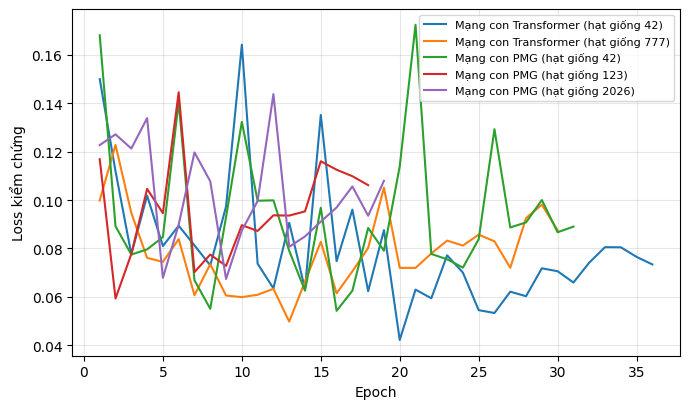

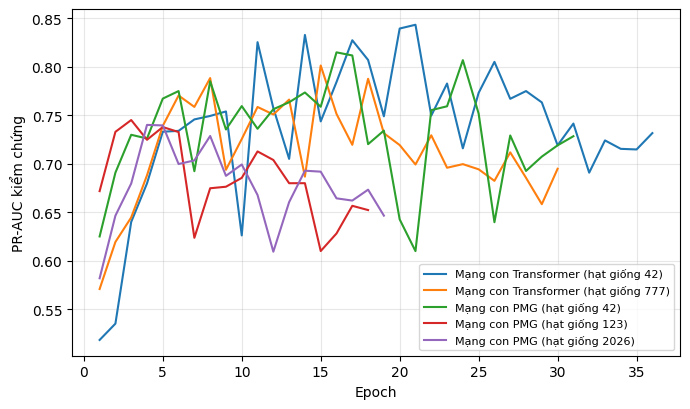

,Mạng con,Số epoch đã chạy,Epoch tốt nhất (val PR-AUC),Train loss,Val loss,Val PR-AUC,Thời gian (phút)
0,Mạng con Transformer (hạt giống 42),36,21,0.0418,0.0630,0.8431,2.2293
1,Mạng con Transformer (hạt giống 777),30,15,0.0604,0.0827,0.8012,1.7938
2,Mạng con PMG (hạt giống 42),31,16,0.0153,0.0542,0.8147,3.3471
3,Mạng con PMG (hạt giống 123),18,3,0.1273,0.0777,0.7450,2.0153
4,Mạng con PMG (hạt giống 2026),19,4,0.0943,0.1338,0.7400,2.0928


Chú thích hình: ghi epoch dừng sớm của từng mạng con theo cột "Số epoch đã chạy".


In [24]:
# ============================================================
# T7. HÌNH HỘI TỤ (Mục 3.3.1) + BẢNG 3.5 (rõ của mạng con nào)
#   Không vẽ Accuracy (gần như bão hòa do mất cân bằng lớp) — theo góp ý của cô.
# ============================================================
import matplotlib.pyplot as plt

hist_files = [('Transformer', s, OUTPUT_DIR/f'history_exp099_transformer_{s}.csv') for s in TRANSFORMER_SEEDS] + \
             [('PMG', s, OUTPUT_DIR/f'history_exp099_pmg_{s}.csv') for s in PMG_SEEDS]

fig1, ax1 = plt.subplots(figsize=(7, 4.2))
fig2, ax2 = plt.subplots(figsize=(7, 4.2))
conv_rows = []
for kind, seed, path in hist_files:
    h = pd.read_csv(path)
    ep = np.arange(1, len(h)+1)
    label = f'Mạng con {kind} (hạt giống {seed})'
    ax1.plot(ep, h['val_loss'], label=label)
    ax2.plot(ep, h['val_pr_auc'], label=label)
    best = int(h['val_pr_auc'].idxmax())
    conv_rows.append({'Mạng con': label, 'Số epoch đã chạy': len(h), 'Epoch tốt nhất (val PR-AUC)': best+1,
                      'Train loss': h.loc[best, 'loss'], 'Val loss': h.loc[best, 'val_loss'],
                      'Val PR-AUC': h.loc[best, 'val_pr_auc'],
                      'Thời gian (phút)': TRAIN_TIMES_S.get(f'{kind.lower()}_{seed}', np.nan)/60})
for ax, yl, fig, fn in [(ax1, 'Loss kiểm chứng', fig1, 'fig_convergence_val_loss.png'),
                        (ax2, 'PR-AUC kiểm chứng', fig2, 'fig_convergence_val_prauc.png')]:
    ax.set_xlabel('Epoch'); ax.set_ylabel(yl); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/fn, dpi=200)
plt.show()

table_3_5 = pd.DataFrame(conv_rows)
display(table_3_5.round(4))
table_3_5.to_csv(OUTPUT_DIR/'table_3_5_convergence_by_submodel.csv', index=False)
print('Chú thích hình: ghi epoch dừng sớm của từng mạng con theo cột "Số epoch đã chạy".')


In [25]:
# ============================================================
# T8. ĐÓNG GÓI KẾT QUẢ ĐỂ TẢI VỀ
# ============================================================
import shutil
zip_path = shutil.make_archive('/kaggle/working/KLTN_EXP_099_outputs', 'zip', OUTPUT_DIR)
print('Tải về:', zip_path)
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {p.name:55s} {p.stat().st_size/1024:8.1f} KB')


Tải về: /kaggle/working/KLTN_EXP_099_outputs.zip
  KLTN_EXP_099_predictions.npz                               115.1 KB
  baseline_v11_vs_v18_test.csv                                 0.8 KB
  best_exp099_pmg_123.keras                                 4976.6 KB
  best_exp099_pmg_2026.keras                                4976.6 KB
  best_exp099_pmg_42.keras                                  4976.6 KB
  best_exp099_transformer_42.keras                          1571.3 KB
  best_exp099_transformer_777.keras                         1571.3 KB
  exp099_subject_balance_weights.csv                           0.6 KB
  exp099_submodel_probs.npz                                  387.1 KB
  exp099_validation_metrics.csv                                0.3 KB
  exp099_validation_metrics_by_subject.csv                     0.4 KB
  exp099_validation_report.json                                0.4 KB
  exp099_validation_report_compact.csv                         0.2 KB
  exp099_window_predictions.csv          